In [1]:
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim
import xgboost as xgb
import numpy as np
import utils
import seaborn as sns


from utils import (
    calculate_technical_indicators,
    compare_results,
    evaluate_predictions,
    evaluate_torch_model,
    fit_arima,
    fit_standard_scaler,
    forecast_arima,
    grid_search_arima,
    load_fred_data,
    normalize_to_tensor,
    plot_dataset,
    plot_predictions_vs_targets,
    predict_and_store_log_return_model,
    predict_moving_average,
    predict_naive,
    prepare_data,
    split_data,
    store_model_prediction,
    train_torch_model,
    train_xgboost,
)

DATA_DIR = Path("FRED")
RESULTS_PATH = Path("model_results.json")
TARGET_COLUMN = "INR"
FEATURE_COLUMNS = ["JPY", "EUR", "FFER", "US10YY"]
TRAIN_FRACTION = 0.8
VALIDATION_FRACTION = 0.1
EPOCHS = 100
BATCH_SIZE = 32
model_results = {}

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Using device: {DEVICE}")

Using device: cuda


In [2]:
full_df = prepare_data(load_fred_data(DATA_DIR))
full_df["TARGET_NEXT"] = full_df[TARGET_COLUMN].shift(-1)
full_df = full_df.dropna(subset=["TARGET_NEXT"])

train_df, val_df, test_df = split_data(
    full_df,
    train_fraction=TRAIN_FRACTION,
    validation_fraction=VALIDATION_FRACTION,
)

full_df.head()

,INR,JPY,EUR,FFER,US10YY,TARGET_NEXT
observation_date,,,,,,
1999-01-04,42.60,112.15,1.1812,5.04,4.69,42.56
1999-01-05,42.56,111.15,1.1760,4.54,4.74,42.55
1999-01-06,42.55,112.78,1.1636,4.23,4.73,42.55
1999-01-07,42.55,111.69,1.1672,4.49,4.77,42.55
1999-01-08,42.55,111.52,1.1554,4.74,4.86,42.55


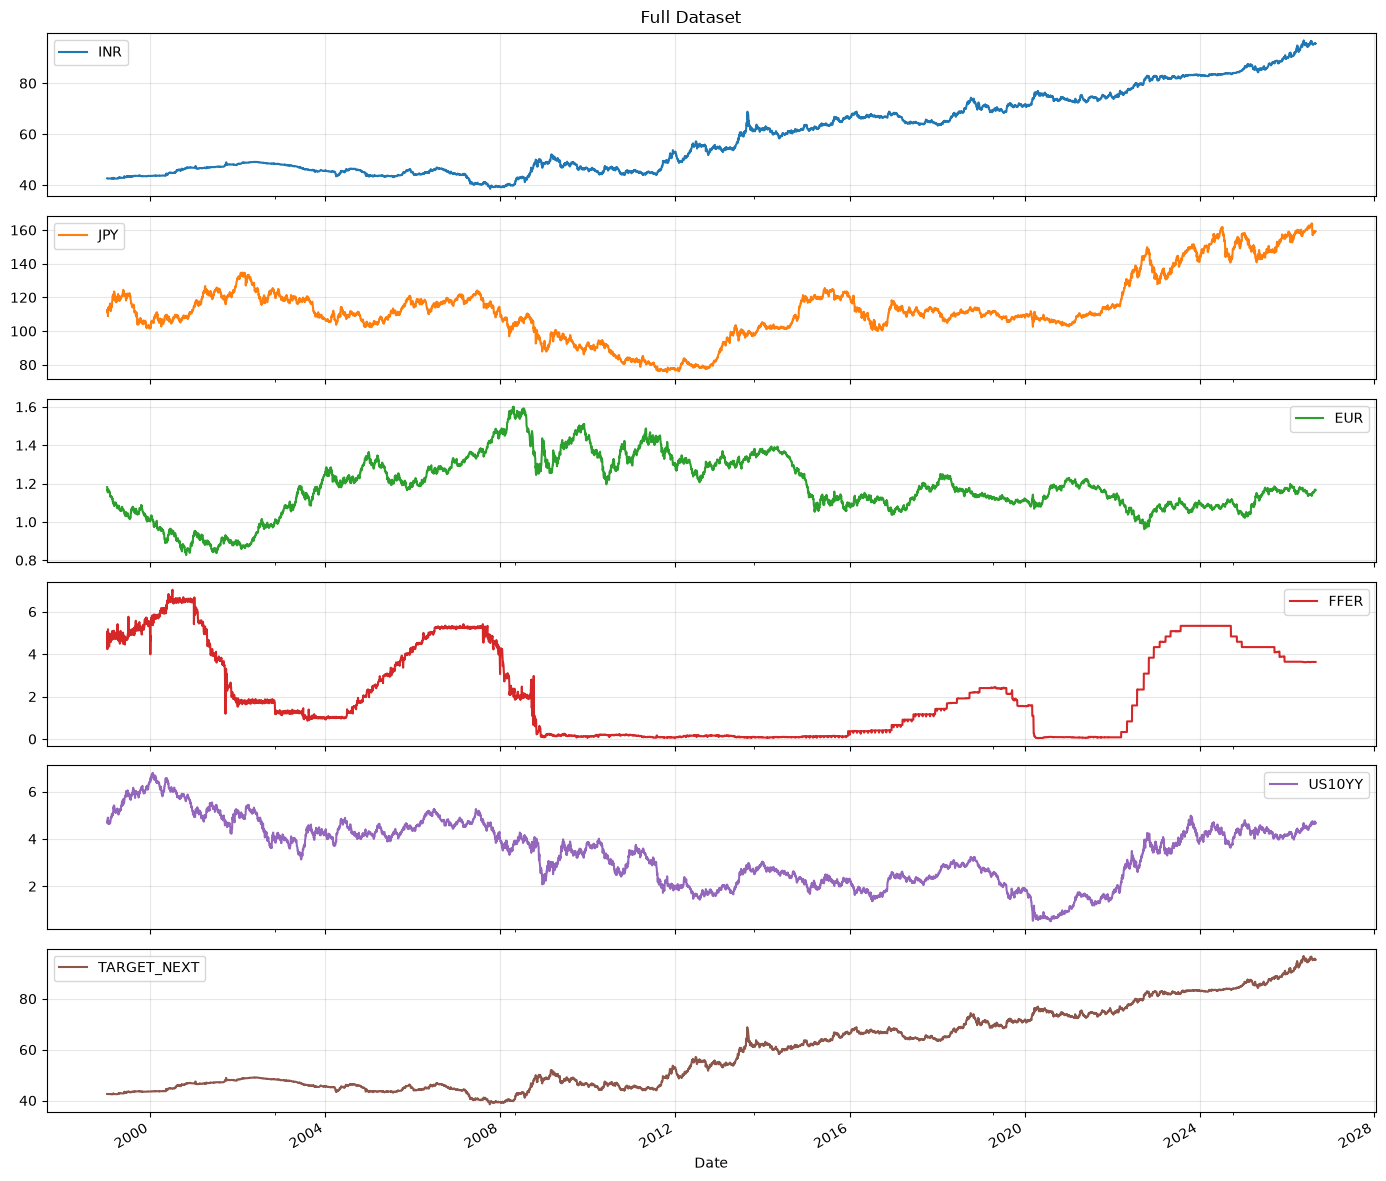

Train: (5524, 6), validation: (690, 6), test: (691, 6)


In [3]:
plot_dataset(full_df)
print(f"Train: {train_df.shape}, validation: {val_df.shape}, test: {test_df.shape}")

## Baseline and ARIMA

Naive: {'mae': 0.1493805826271353, 'mse': 0.07776622105608079, 'rmse': 0.27886595535504294, 'directional_accuracy': 53.08709034944776, 'correct_days': 2932, 'total_days': 5523}
Moving average: {'mae': 0.11185312760039676, 'mse': 0.07249965294511787, 'rmse': 0.2692575958912169, 'directional_accuracy': 78.20025348542458, 'correct_days': 4319, 'total_days': 5523}


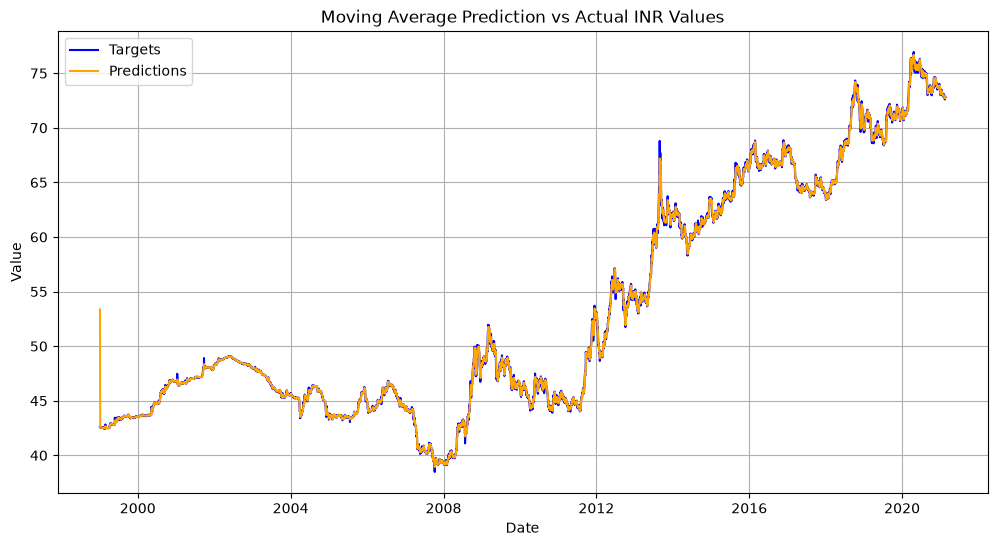

In [4]:
naive_predictions = predict_naive(train_df, TARGET_COLUMN)
moving_average_predictions = predict_moving_average(train_df, target_column=TARGET_COLUMN)

naive_metrics = evaluate_predictions(naive_predictions, train_df[TARGET_COLUMN])
moving_average_metrics = evaluate_predictions(
    moving_average_predictions,
    train_df[TARGET_COLUMN],
)
store_model_prediction(
    model_results,
    "Naive",
    naive_predictions,
    naive_metrics,
    "train",
)
store_model_prediction(
    model_results,
    "Moving Average",
    moving_average_predictions,
    moving_average_metrics,
    "train",
)
print("Naive:", naive_metrics)
print("Moving average:", moving_average_metrics)
plot_predictions_vs_targets(
    moving_average_predictions,
    train_df[TARGET_COLUMN],
    x_values=train_df.index,
    title="Moving Average Prediction vs Actual INR Values",
)

c:\Users\xprin\Desktop\AIML\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\xprin\Desktop\AIML\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\xprin\Desktop\AIML\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\xprin\Desktop\AIML\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\xprin\Desktop\AIML\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to co

        order       mae          aic
13  (2, 0, 1)  1.189463  1083.986231
14  (2, 0, 2)  3.967801  1110.132852
7   (1, 0, 1)  4.096017   981.965548
12  (2, 0, 0)  4.323510   985.545433
6   (1, 0, 0)  4.422338   987.722667
Best ARIMA order: (2, 0, 1)


c:\Users\xprin\Desktop\AIML\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


{'mae': 1.1894633706751412, 'mse': 2.3348702134278048, 'rmse': 1.5280282109397734, 'directional_accuracy': 53.84615384615385, 'correct_days': 371, 'total_days': 689}


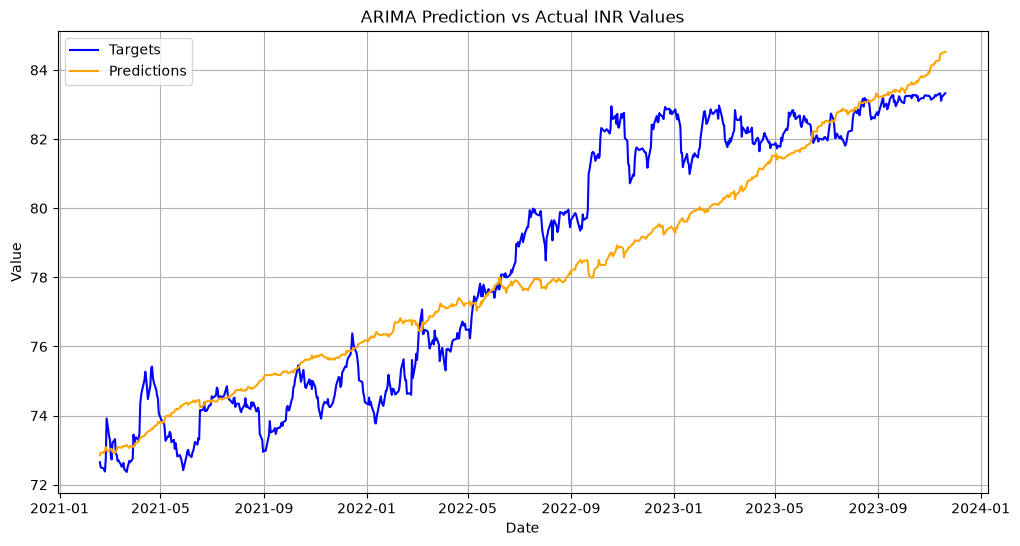

In [5]:
search_results, best_order = grid_search_arima(
    train_df,
    val_df,
    FEATURE_COLUMNS,
    p_values=range(0, 3),
    d_values=range(0, 2),
    q_values=range(0, 3),
    target_column=TARGET_COLUMN,
)
print(search_results.head())
print(f"Best ARIMA order: {best_order}")
arima_model = fit_arima(train_df, FEATURE_COLUMNS, best_order, TARGET_COLUMN)
arima_train_predictions = arima_model.predict(
    start=0,
    end=len(train_df) - 1,
    exog=train_df[FEATURE_COLUMNS],
)
arima_predictions, arima_metrics = forecast_arima(
    arima_model,
    val_df,
    FEATURE_COLUMNS,
    TARGET_COLUMN,
)
arima_train_metrics = evaluate_predictions(
    arima_train_predictions,
    train_df[TARGET_COLUMN],
)
store_model_prediction(
    model_results,
    "ARIMA",
    arima_train_predictions,
    arima_train_metrics,
    "train",
)
store_model_prediction(
    model_results,
    "ARIMA",
    arima_predictions,
    arima_metrics,
    "validation",
)
print(arima_metrics)
plot_predictions_vs_targets(
    arima_predictions,
    val_df[TARGET_COLUMN],
    x_values=val_df.index,
    title="ARIMA Prediction vs Actual INR Values",
)

## XGBoost

[0]	validation_0-rmse:10.25372	validation_1-rmse:25.29351	validation_2-rmse:34.48110
[100]	validation_0-rmse:1.07601	validation_1-rmse:26.19632	validation_2-rmse:43.18526
[200]	validation_0-rmse:0.70740	validation_1-rmse:26.17821	validation_2-rmse:43.63768
[300]	validation_0-rmse:0.61798	validation_1-rmse:26.15898	validation_2-rmse:43.68659
[400]	validation_0-rmse:0.55267	validation_1-rmse:26.14245	validation_2-rmse:43.69870
[499]	validation_0-rmse:0.50368	validation_1-rmse:26.11360	validation_2-rmse:43.67179
{'mae': 43.520977324997816, 'mse': 1907.2248406795463, 'rmse': 43.67178540750935, 'directional_accuracy': 44.927536231884055, 'correct_days': 310, 'total_days': 690}


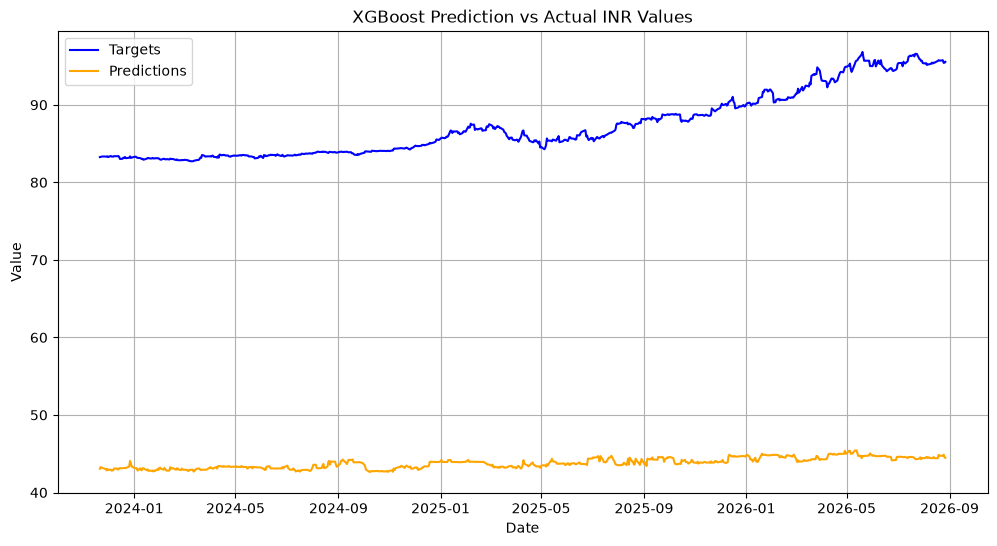

In [6]:
xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
)
xgb_model = train_xgboost(
    xgb_model,
    train_df,
    val_df,
    test_df,
    FEATURE_COLUMNS,
    TARGET_COLUMN,
)
xgb_train_predictions = xgb_model.predict(train_df[FEATURE_COLUMNS])
xgb_test_predictions = xgb_model.predict(test_df[FEATURE_COLUMNS])
xgb_train_metrics = evaluate_predictions(
    xgb_train_predictions,
    train_df[TARGET_COLUMN],
)
xgb_metrics = evaluate_predictions(
    xgb_test_predictions,
    test_df[TARGET_COLUMN],
)
store_model_prediction(
    model_results,
    "XGBoost",
    xgb_train_predictions,
    xgb_train_metrics,
    "train",
)
store_model_prediction(
    model_results,
    "XGBoost",
    xgb_test_predictions,
    xgb_metrics,
    "test",
)
print(xgb_metrics)
plot_predictions_vs_targets(
    xgb_test_predictions,
    test_df[TARGET_COLUMN],
    x_values=test_df.index,
    title="XGBoost Prediction vs Actual INR Values",
)

In [7]:
baseline_feature_columns = FEATURE_COLUMNS + [TARGET_COLUMN]
X_train = torch.tensor(
    train_df[baseline_feature_columns].values,
    dtype=torch.float32,
)
y_train = torch.tensor(
    train_df[TARGET_COLUMN].shift(-1).interpolate(limit_direction="both").values,
    dtype=torch.float32,
).view(-1, 1)
X_val = torch.tensor(
    val_df[baseline_feature_columns].values,
    dtype=torch.float32,
)
y_val = torch.tensor(
    val_df[TARGET_COLUMN].shift(-1).interpolate(limit_direction="both").values,
    dtype=torch.float32,
).view(-1, 1)
X_test = torch.tensor(
    test_df[baseline_feature_columns].values,
    dtype=torch.float32,
)
y_test = torch.tensor(
    test_df[TARGET_COLUMN].shift(-1).interpolate(limit_direction="both").values,
    dtype=torch.float32,
).view(-1, 1)

NUM_INPUT_FEATURES = X_train.shape[1]
OUTPUT_FEATURES = 1

linear_model = nn.Linear(NUM_INPUT_FEATURES, OUTPUT_FEATURES)
linear_optimizer = optim.Adam(linear_model.parameters(), lr=0.01)
linear_losses = train_torch_model(
    linear_model,
    linear_optimizer,
    nn.MSELoss(),
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

deep_model = nn.Sequential(
    nn.Linear(NUM_INPUT_FEATURES, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, OUTPUT_FEATURES),
)
deep_optimizer = optim.Adam(deep_model.parameters(), lr=0.01)
deep_losses = train_torch_model(
    deep_model,
    deep_optimizer,
    nn.MSELoss(),
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

with torch.no_grad():
    linear_train_predictions = linear_model(X_train)
    linear_test_predictions = linear_model(X_test)
    deep_train_predictions = deep_model(X_train)
    deep_test_predictions = deep_model(X_test)

linear_train_metrics = evaluate_predictions(linear_train_predictions, y_train)
linear_metrics = evaluate_predictions(linear_test_predictions, y_test)
deep_train_metrics = evaluate_predictions(deep_train_predictions, y_train)
deep_metrics = evaluate_predictions(deep_test_predictions, y_test)

store_model_prediction(
    model_results,
    "Linear Regression",
    linear_train_predictions,
    linear_train_metrics,
    "train",
)
store_model_prediction(
    model_results,
    "Linear Regression",
    linear_test_predictions,
    linear_metrics,
    "test",
)
store_model_prediction(
    model_results,
    "Deep Learning",
    deep_train_predictions,
    deep_train_metrics,
    "train",
)
store_model_prediction(
    model_results,
    "Deep Learning",
    deep_test_predictions,
    deep_metrics,
    "test",
)

print(f"Linear Regression test metrics: {linear_metrics}")
print(f"Deep Learning test metrics: {deep_metrics}")

Epoch 10/100, Train Loss: 7723.3345, Val Loss: 14689.7910
Epoch 20/100, Train Loss: 5153.0146, Val Loss: 10139.5215
Epoch 30/100, Train Loss: 3233.9453, Val Loss: 6671.6348
Epoch 40/100, Train Loss: 1906.3617, Val Loss: 4194.9717
Epoch 50/100, Train Loss: 1060.5961, Val Loss: 2537.8259
Epoch 60/100, Train Loss: 568.0560, Val Loss: 1497.2325
Epoch 70/100, Train Loss: 308.2969, Val Loss: 881.2748
Epoch 80/100, Train Loss: 185.6486, Val Loss: 534.7574
Epoch 90/100, Train Loss: 134.4492, Val Loss: 347.3600
Epoch 100/100, Train Loss: 115.6580, Val Loss: 248.9012
Epoch 10/100, Train Loss: 519.5138, Val Loss: 186.7244
Epoch 20/100, Train Loss: 159.6748, Val Loss: 348.3217
Epoch 30/100, Train Loss: 61.7540, Val Loss: 42.0114
Epoch 40/100, Train Loss: 34.7519, Val Loss: 45.3727
Epoch 50/100, Train Loss: 23.5963, Val Loss: 71.0732
Epoch 60/100, Train Loss: 14.9325, Val Loss: 9.3707
Epoch 70/100, Train Loss: 6.0535, Val Loss: 10.8506
Epoch 80/100, Train Loss: 2.9049, Val Loss: 10.1349
Epoch 90/10

## Technical indicators

In [6]:
technical_data = calculate_technical_indicators(full_df).dropna()
technical_data["TARGET_NEXT"] = technical_data["Log_Returns"].shift(-1)
technical_data = technical_data.dropna(subset=["TARGET_NEXT"])
technical_data.head()

,INR,JPY,EUR,FFER,US10YY,TARGET_NEXT,MA_5,MA_10,MA_30,MA_50,...,EMA_50,EMA_100,RSI,BB_Middle,BB_Upper,BB_Lower,Volatility,ATR_14_proxy,ATR_%_proxy,Log_Returns
observation_date,,,,,,,,,,,,,,,,,,,,,
1999-05-25,42.80,122.88,1.0587,4.80,5.49,0.003499,42.800,42.796,42.831000,42.7324,...,42.748324,42.686452,50.000000,42.8105,42.873571,42.747429,0.031535,0.010000,0.023364,0.000000
1999-05-26,42.95,122.03,1.0471,4.81,5.55,0.011574,42.830,42.811,42.834333,42.7414,...,42.756233,42.691671,75.862069,42.8130,42.892763,42.733237,0.039881,0.020714,0.048229,0.003499
1999-05-27,43.45,121.27,1.0439,4.87,5.62,-0.006465,42.960,42.876,42.852667,42.7604,...,42.783440,42.706688,91.139241,42.8425,43.138571,42.546429,0.148035,0.056429,0.129870,0.011574
1999-05-28,43.17,120.88,1.0422,4.61,5.64,-0.003946,43.034,42.910,42.866667,42.7738,...,42.798599,42.715862,67.289720,42.8590,43.189289,42.528711,0.165144,0.076429,0.177041,-0.006465
1999-06-01,43.00,120.75,1.0449,4.78,5.78,0.000000,43.074,42.934,42.868333,42.7838,...,42.806497,42.721489,58.064516,42.8665,43.202688,42.530312,0.168094,0.088571,0.205980,-0.003946


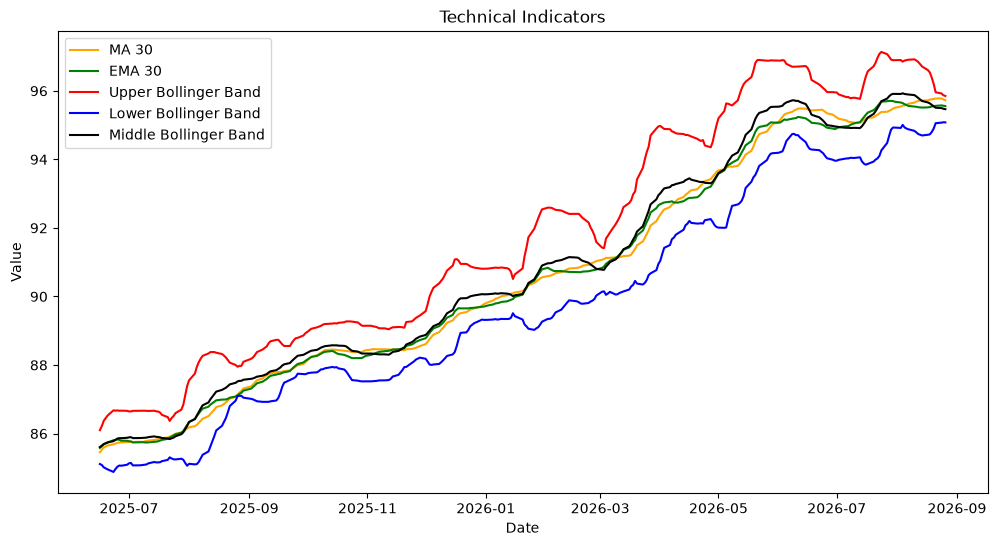

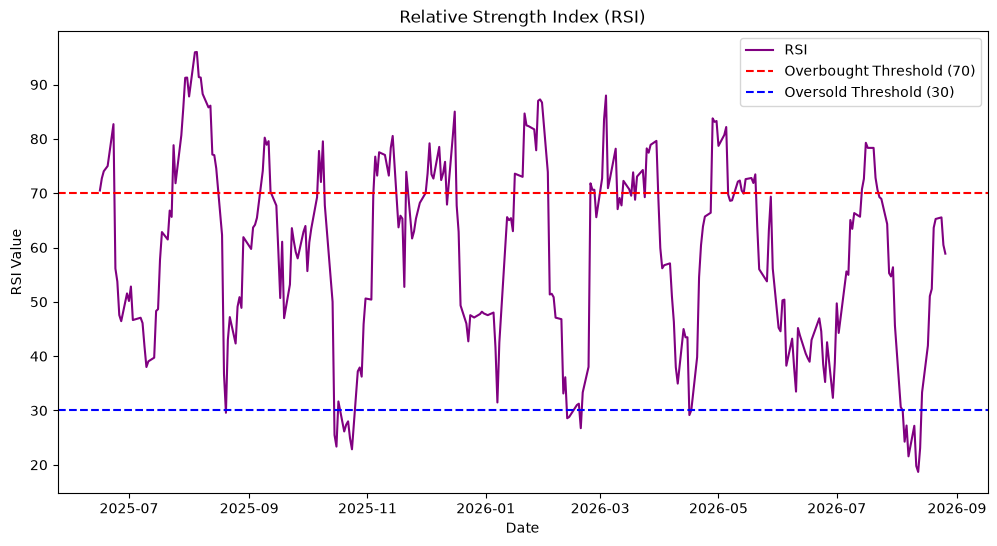

In [7]:
# Plot data with technical indicators - MA30, EMA30, RSI, bollinger bands
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(technical_data[-300:].index, technical_data[-300:]["MA_30"], label="MA 30", color="orange")
plt.plot(technical_data[-300:].index, technical_data[-300:]["EMA_30"], label="EMA 30", color="green")
plt.plot(technical_data[-300:].index, technical_data[-300:]["BB_Upper"], label="Upper Bollinger Band", color="red")
plt.plot(technical_data[-300:].index, technical_data[-300:]["BB_Lower"], label="Lower Bollinger Band", color="blue")
plt.plot(technical_data[-300:].index, technical_data[-300:]["BB_Middle"], label="Middle Bollinger Band", color="black")
plt.title("Technical Indicators")
plt.xlabel("Date")
plt.ylabel("Value")
plt.legend()
plt.show()

## RSI
plt.figure(figsize=(12, 6))
plt.plot(technical_data[-300:].index, technical_data[-300:]["RSI"], label="RSI", color="purple")
plt.title("Relative Strength Index (RSI)")
plt.xlabel("Date")
plt.ylabel("RSI Value")
plt.axhline(70, color="red", linestyle="--", label="Overbought Threshold (70)")
plt.axhline(30, color="blue", linestyle="--", label="Oversold Threshold (30)")
plt.legend()
plt.show()

### Analysis of tecchnical data

<Axes: >

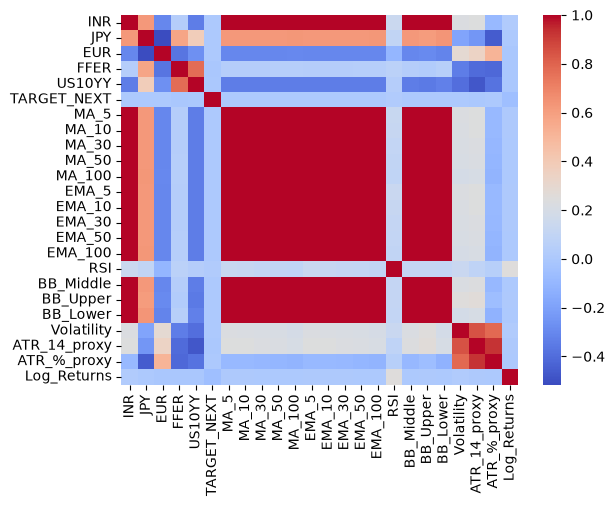

In [8]:
##  code to plot the technical indicators

sns.heatmap(technical_data.corr(), cmap="coolwarm")

In [9]:
NUM_INPUT_FEATURES = len(FEATURE_COLUMNS) + 1 + 12  # Original features + target + technical indicators
OUTPUT_FEATURES = 1  # Predicting the next price

train_df_ta, val_df_ta, test_df_ta = split_data(
    technical_data,
    train_fraction=TRAIN_FRACTION,
    validation_fraction=VALIDATION_FRACTION,
)

In [10]:
ta_columns = [
    "MA_5",
    "MA_10",
    "MA_30",
    "MA_50",
    "MA_100",
    "EMA_5",
    "EMA_10",
    "EMA_30",
    "EMA_50",
    "EMA_100",
    "RSI",
    "BB_Middle",
    "BB_Upper",
    "BB_Lower",
    "Volatility",
    "ATR_14_proxy",
    "ATR_%_proxy",
    "Log_Returns",
]

all_features = FEATURE_COLUMNS + [TARGET_COLUMN] + ta_columns

In [11]:
TARGET_COLUMN = "INR"
technical_target_column = "TARGET_NEXT"

In [12]:
feature_scaler = fit_standard_scaler(train_df_ta, all_features)

train_targets = train_df_ta["TARGET_NEXT"]
val_targets = val_df_ta["TARGET_NEXT"]
test_targets = test_df_ta["TARGET_NEXT"]
target_scaler = fit_standard_scaler(train_targets)

X_train = normalize_to_tensor(train_df_ta, feature_scaler, all_features)
X_val = normalize_to_tensor(val_df_ta, feature_scaler, all_features)
X_test = normalize_to_tensor(test_df_ta, feature_scaler, all_features)
y_train = normalize_to_tensor(train_targets, target_scaler)
y_val = normalize_to_tensor(val_targets, target_scaler)
y_test = normalize_to_tensor(test_targets, target_scaler)

NUM_INPUT_FEATURES = X_train.shape[1]
OUTPUT_FEATURES = 1

In [13]:
model_linear_ta = nn.Linear(NUM_INPUT_FEATURES, OUTPUT_FEATURES)
model_linear_ta_optimizer = optim.Adam(
    model_linear_ta.parameters(),
    lr=0.001,
)
model_linear_ta_loss_function = nn.MSELoss()

In [14]:
EPOCHS = 100

model_linear_ta_losses = train_torch_model(
    model_linear_ta,
    model_linear_ta_optimizer,
    model_linear_ta_loss_function,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

Epoch 10/100, Train Loss: 1.6339, Val Loss: 2.2416
Epoch 20/100, Train Loss: 1.4383, Val Loss: 1.4761
Epoch 30/100, Train Loss: 1.2946, Val Loss: 0.9650
Epoch 40/100, Train Loss: 1.1966, Val Loss: 0.6682
Epoch 50/100, Train Loss: 1.1339, Val Loss: 0.5277
Epoch 60/100, Train Loss: 1.0956, Val Loss: 0.4831
Epoch 70/100, Train Loss: 1.0723, Val Loss: 0.4849
Epoch 80/100, Train Loss: 1.0574, Val Loss: 0.5004
Epoch 90/100, Train Loss: 1.0469, Val Loss: 0.5134
Epoch 100/100, Train Loss: 1.0389, Val Loss: 0.5189


Test MAE: 0.2667, Test MSE: 0.1126


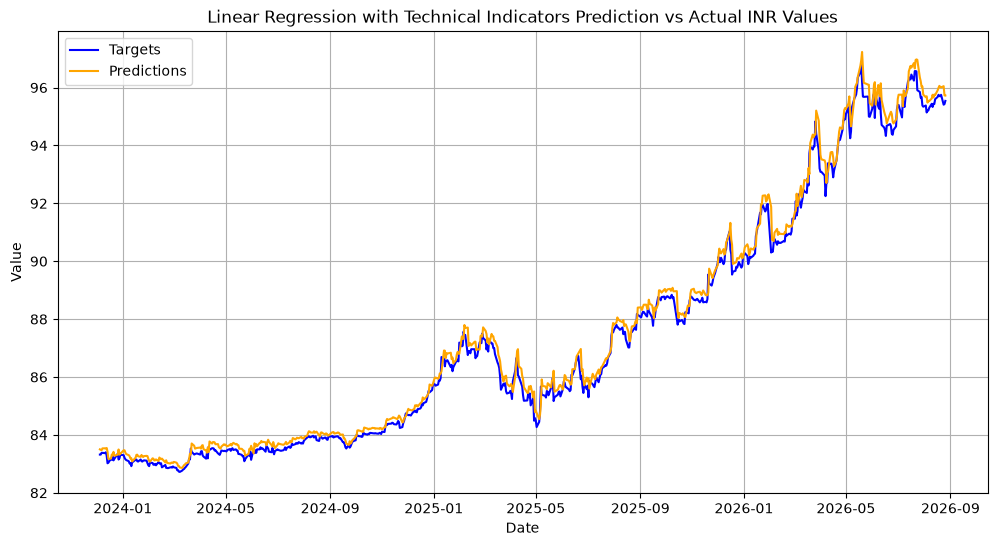

In [15]:
linear_ta_prediction_results = predict_and_store_log_return_model(
    model=model_linear_ta,
    model_name="Linear Regression with Technical Indicators",
    train_inputs=X_train,
    test_inputs=X_test,
    train_targets=y_train,
    test_targets=y_test,
    train_current_prices=train_df_ta["INR"].values,
    test_current_prices=test_df_ta["INR"].values,
    target_scaler=target_scaler,
    model_results=model_results,
    output_path=RESULTS_PATH,
)

predicted_train_prices_linear_ta = linear_ta_prediction_results["train_predictions"]
predicted_prices_linear_ta = linear_ta_prediction_results["test_predictions"]
actual_train_prices_ta = linear_ta_prediction_results["train_actual_prices"]
actual_prices_ta = linear_ta_prediction_results["test_actual_prices"]
linear_ta_train_metrics = linear_ta_prediction_results["train_metrics"]
linear_ta_metrics = linear_ta_prediction_results["test_metrics"]

print(
    f"Test MAE: {linear_ta_metrics['mae']:.4f}, "
    f"Test MSE: {linear_ta_metrics['mse']:.4f}"
)
plot_predictions_vs_targets(
    predicted_prices_linear_ta,
    actual_prices_ta,
    x_values=test_df_ta.index,
    title="Linear Regression with Technical Indicators Prediction vs Actual INR Values",
)

In [16]:
model_dl_ta = nn.Sequential(
    nn.Linear(NUM_INPUT_FEATURES, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)
model_dl_ta_optimizer = optim.Adam(
    model_dl_ta.parameters(),
    lr=0.001,
)
model_dl_ta_loss_function = nn.MSELoss()

In [17]:
train_losses_dl_ta = train_torch_model(
    model_dl_ta,
    model_dl_ta_optimizer,
    model_dl_ta_loss_function,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

Epoch 10/100, Train Loss: 1.0001, Val Loss: 0.4108
Epoch 20/100, Train Loss: 0.9937, Val Loss: 0.4107
Epoch 30/100, Train Loss: 0.9897, Val Loss: 0.4086
Epoch 40/100, Train Loss: 0.9865, Val Loss: 0.4103
Epoch 50/100, Train Loss: 0.9837, Val Loss: 0.4106
Epoch 60/100, Train Loss: 0.9809, Val Loss: 0.4108
Epoch 70/100, Train Loss: 0.9781, Val Loss: 0.4109
Epoch 80/100, Train Loss: 0.9750, Val Loss: 0.4111
Epoch 90/100, Train Loss: 0.9718, Val Loss: 0.4115
Epoch 100/100, Train Loss: 0.9681, Val Loss: 0.4124


Test MAE: 0.1461, Test MSE: 0.0532


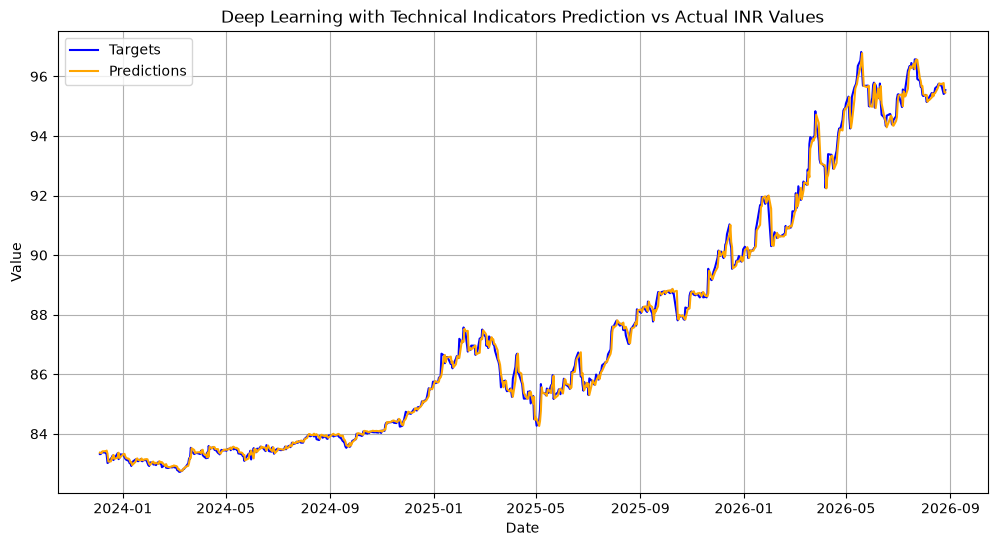

In [18]:
deep_ta_prediction_results = predict_and_store_log_return_model(
    model=model_dl_ta,
    model_name="Deep Learning with Technical Indicators",
    train_inputs=X_train,
    test_inputs=X_test,
    train_targets=y_train,
    test_targets=y_test,
    train_current_prices=train_df_ta["INR"].values,
    test_current_prices=test_df_ta["INR"].values,
    target_scaler=target_scaler,
    model_results=model_results,
    output_path=RESULTS_PATH,
)

predicted_train_prices_ta = deep_ta_prediction_results["train_predictions"]
predicted_prices_ta = deep_ta_prediction_results["test_predictions"]
actual_train_prices_ta = deep_ta_prediction_results["train_actual_prices"]
actual_prices_ta = deep_ta_prediction_results["test_actual_prices"]
deep_ta_train_metrics = deep_ta_prediction_results["train_metrics"]
deep_ta_metrics = deep_ta_prediction_results["test_metrics"]

print(
    f"Test MAE: {deep_ta_metrics['mae']:.4f}, "
    f"Test MSE: {deep_ta_metrics['mse']:.4f}"
)
plot_predictions_vs_targets(
    predicted_prices_ta,
    actual_prices_ta,
    x_values=test_df_ta.index,
    title="Deep Learning with Technical Indicators Prediction vs Actual INR Values",
)

## ADD NEW TEMPORAL FEATURES

In [19]:
TEMPORAL_FEATURES_NUMBER = 5  # Number of temporal features to include

In [20]:
import pandas as pd

def create_temporal_features(df, target_columns=None, num_features=5):
    """Add lagged temporal features"""
    df = df.copy()

    if target_columns is None:
        target_columns = [
            column for column in df.columns
            if column != "TARGET_NEXT"
        ]

    lagged_features = [
        df[target_columns]
        .shift(lag)
        .add_suffix(f"_lag_{lag}")
        for lag in range(1, num_features + 1)
    ]

    return pd.concat([df, *lagged_features], axis=1)


In [21]:
train_df_temp = create_temporal_features(
    train_df_ta.copy(),
    None,
    TEMPORAL_FEATURES_NUMBER,
).dropna()
val_df_temp = create_temporal_features(
    val_df_ta.copy(),
    None,
    TEMPORAL_FEATURES_NUMBER,
).dropna()
test_df_temp = create_temporal_features(
    test_df_ta.copy(),
    None,
    TEMPORAL_FEATURES_NUMBER,
).dropna()

In [22]:
train_df_temp.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 5439 entries, 1999-06-02 to 2021-03-16
Columns: 139 entries, INR to Log_Returns_lag_5
dtypes: float64(139)
memory usage: 5.8 MB


In [23]:
temporal_features = all_features + [
    f"{feature}_lag_{lag}"
    for feature in all_features
    for lag in range(1, TEMPORAL_FEATURES_NUMBER + 1)
]

feature_scaler_temp = fit_standard_scaler(train_df_temp, temporal_features)

train_targets = train_df_temp["TARGET_NEXT"]
val_targets = val_df_temp["TARGET_NEXT"]
test_targets = test_df_temp["TARGET_NEXT"]
target_scaler = fit_standard_scaler(train_targets)

X_train = normalize_to_tensor(train_df_temp, feature_scaler_temp, temporal_features)
X_val = normalize_to_tensor(val_df_temp, feature_scaler_temp, temporal_features)
X_test = normalize_to_tensor(test_df_temp, feature_scaler_temp, temporal_features)
y_train = normalize_to_tensor(train_targets, target_scaler)
y_val = normalize_to_tensor(val_targets, target_scaler)
y_test = normalize_to_tensor(test_targets, target_scaler)

NUM_INPUT_FEATURES = X_train.shape[1]
OUTPUT_FEATURES = 1

In [24]:
model_dl_temp = nn.Sequential(
    nn.Linear(NUM_INPUT_FEATURES, 64),
    nn.ReLU(),
    nn.Dropout(0.2),

    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Dropout(0.2),

    nn.Linear(32, 1)
)
model_dl_temp_optimizer = optim.Adam(
    model_dl_temp.parameters(),
    lr=0.001,
)
model_dl_temp_loss_function = nn.MSELoss()

In [25]:
train_losses_dl_temp = train_torch_model(
    model_dl_temp,
    model_dl_temp_optimizer,
    model_dl_temp_loss_function,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

Epoch 10/100, Train Loss: 1.0059, Val Loss: 0.4154
Epoch 20/100, Train Loss: 0.9943, Val Loss: 0.4153
Epoch 30/100, Train Loss: 0.9920, Val Loss: 0.4192
Epoch 40/100, Train Loss: 0.9859, Val Loss: 0.4321
Epoch 50/100, Train Loss: 0.9789, Val Loss: 0.4254
Epoch 60/100, Train Loss: 0.9783, Val Loss: 0.4242
Epoch 70/100, Train Loss: 0.9685, Val Loss: 0.4267
Epoch 80/100, Train Loss: 0.9583, Val Loss: 0.4230
Epoch 90/100, Train Loss: 0.9651, Val Loss: 0.4308
Epoch 100/100, Train Loss: 0.9501, Val Loss: 0.4328


Test MAE: 0.1624, Test MSE: 0.0599


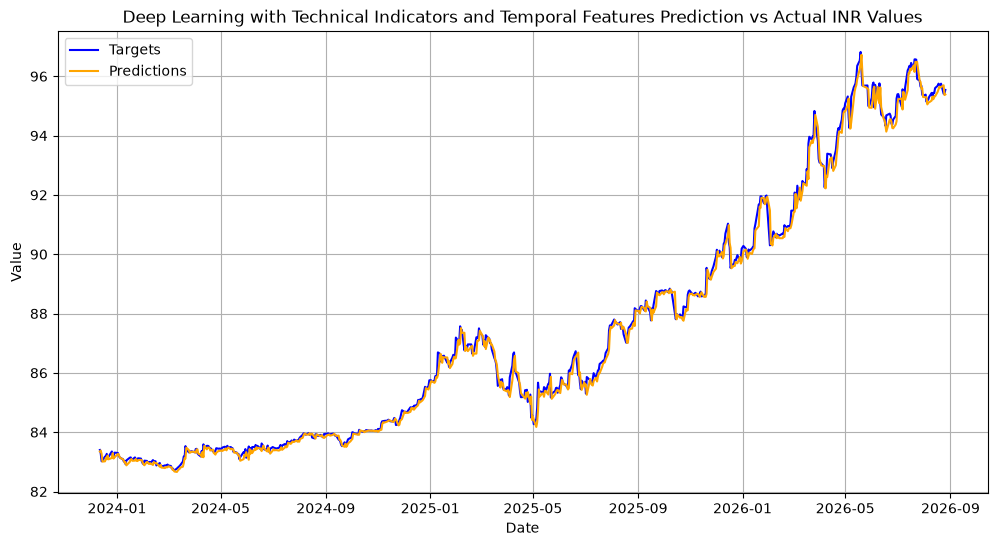

In [26]:
deep_temp_prediction_results = predict_and_store_log_return_model(
    model=model_dl_temp,
    model_name="Deep Learning with Technical Indicators and Temporal Features",
    train_inputs=X_train,
    test_inputs=X_test,
    train_targets=y_train,
    test_targets=y_test,
    train_current_prices=train_df_temp["INR"].values,
    test_current_prices=test_df_temp["INR"].values,
    target_scaler=target_scaler,
    model_results=model_results,
    output_path=RESULTS_PATH,
)

predicted_train_prices_temp = deep_temp_prediction_results["train_predictions"]
predicted_prices_temp = deep_temp_prediction_results["test_predictions"]
actual_train_prices_temp = deep_temp_prediction_results["train_actual_prices"]
actual_prices_temp = deep_temp_prediction_results["test_actual_prices"]
deep_temp_train_metrics = deep_temp_prediction_results["train_metrics"]
deep_temp_metrics = deep_temp_prediction_results["test_metrics"]

print(
    f"Test MAE: {deep_temp_metrics['mae']:.4f}, "
    f"Test MSE: {deep_temp_metrics['mse']:.4f}"
)
plot_predictions_vs_targets(
    predicted_prices_temp,
    actual_prices_temp,
    x_values=test_df_temp.index,
    title="Deep Learning with Technical Indicators and Temporal Features Prediction vs Actual INR Values",
)

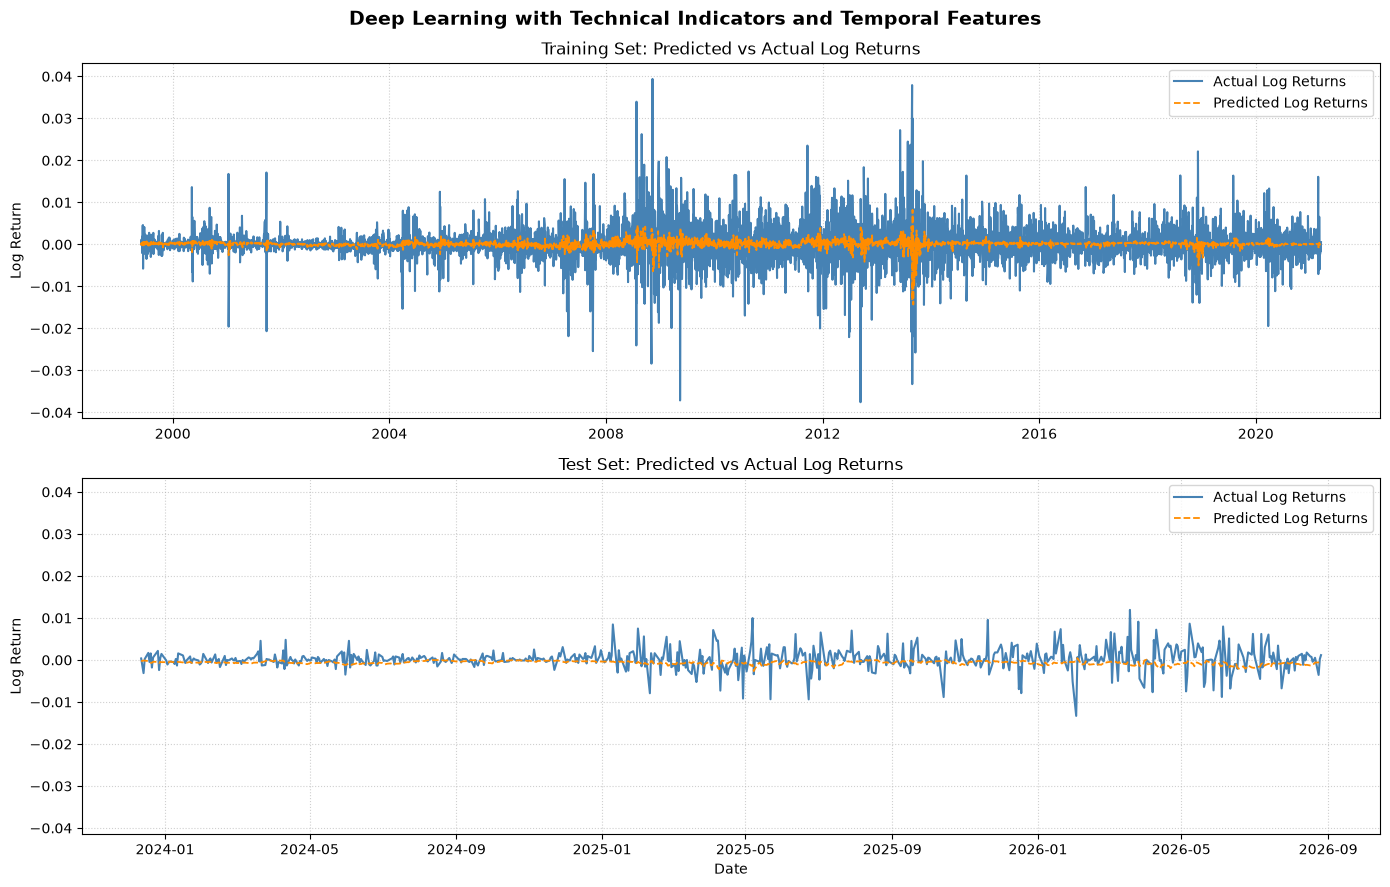

In [27]:
# PLOT PREDICTED LOG RETURNS vs ACTUAL LOG RETURNS
import matplotlib.pyplot as plt

predicted_train_log_returns = np.log(
    predicted_train_prices_temp / train_df_temp["INR"].to_numpy()
)
actual_train_log_returns = np.log(
    actual_train_prices_temp / train_df_temp["INR"].to_numpy()
)
predicted_test_log_returns = np.log(
    predicted_prices_temp / test_df_temp["INR"].to_numpy()
)
actual_test_log_returns = np.log(
    actual_prices_temp / test_df_temp["INR"].to_numpy()
)

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharey=True)

axes[0].plot(
    train_df_temp.index,
    actual_train_log_returns,
    label="Actual Log Returns",
    color="steelblue",
    linewidth=1.5,
)
axes[0].plot(
    train_df_temp.index,
    predicted_train_log_returns,
    label="Predicted Log Returns",
    color="darkorange",
    linestyle="--",
    linewidth=1.3,
)
axes[0].set_title("Training Set: Predicted vs Actual Log Returns")
axes[0].set_ylabel("Log Return")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

axes[1].plot(
    test_df_temp.index,
    actual_test_log_returns,
    label="Actual Log Returns",
    color="steelblue",
    linewidth=1.5,
)
axes[1].plot(
    test_df_temp.index,
    predicted_test_log_returns,
    label="Predicted Log Returns",
    color="darkorange",
    linestyle="--",
    linewidth=1.3,
)
axes[1].set_title("Test Set: Predicted vs Actual Log Returns")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Log Return")
axes[1].legend()
axes[1].grid(True, linestyle=":", alpha=0.6)

fig.suptitle(
    "Deep Learning with Technical Indicators and Temporal Features",
    fontsize=14,
    fontweight="bold",
)
fig.tight_layout()
plt.show()

## LSTM Model with Technical Indicators (Target: Log Returns + Directional Loss)

Financial log returns have a very low signal-to-noise ratio. A standard Mean Squared Error (MSE) loss causes the model to simply predict the mean (near zero) to minimize error, resulting in a flat-line prediction.

To fix this 'mean-seeking' behavior, we apply three fixes:
1. **Big-Move Aware Directional Loss**: Adds a heavy penalty when the predicted sign (Up/Down) doesn't match the actual sign, forcing the model to take a stance.
2. **Reduce Model Complexity**: Use 1 LSTM layer with 32 units to prevent the optimizer from getting stuck over-regularizing.
3. **Shorten Lookback Window**: Use 10 days instead of 30 to focus on recent price action rather than distant noise.

In [28]:
# ────────────────────────────────────────────────────────────────────────────
# Prepare technical-indicator data for the LSTM model
# ────────────────────────────────────────────────────────────────────────────
from utils import (
    create_time_series_dataloaders,
    train_torch_model_dataloader,
    predict_and_store_window_model,
    evaluate_torch_model_dataloader,
    plot_predictions_vs_targets,
)
import torch
import torch.nn as nn
import torch.optim as optim

lstm_df = calculate_technical_indicators(full_df, target_column=TARGET_COLUMN)
lstm_df["TARGET_LOG_RETURN_NEXT"] = lstm_df["Log_Returns"].shift(-1)
lstm_df = lstm_df.dropna()

LSTM_FEATURE_COLS = [
    TARGET_COLUMN,
    *FEATURE_COLUMNS,
    "MA_5", "MA_10", "MA_30", "MA_50", "MA_100",
    "EMA_5", "EMA_10", "EMA_30", "EMA_50", "EMA_100",
    "RSI",
    "BB_Middle", "BB_Upper", "BB_Lower",
    "Volatility",
    "ATR_14_proxy", "ATR_%_proxy",
    "Log_Returns",
]

LSTM_WINDOW_SIZE = 10     # Shorter window to focus on recent price action
LSTM_HIDDEN_SIZE = 32     # Smaller network to avoid mean-collapse
LSTM_NUM_LAYERS = 1
LSTM_DROPOUT = 0.0
LSTM_LR = 1e-3
LSTM_EPOCHS = 80
LSTM_BATCH_SIZE = 32
LSTM_PATIENCE = 10

print(f"LSTM dataframe shape: {lstm_df.shape}")


LSTM dataframe shape: (6805, 25)


In [29]:
# ────────────────────────────────────────────────────────────────────────────
# Create windowed dataloaders predicting Log Returns
# ────────────────────────────────────────────────────────────────────────────
lstm_loaders = create_time_series_dataloaders(
    data=lstm_df,
    target_column="TARGET_LOG_RETURN_NEXT",
    feature_columns=LSTM_FEATURE_COLS,
    window_size=LSTM_WINDOW_SIZE,
    offset=0,
    target_size=1,
    stride=1,
    batch_size=LSTM_BATCH_SIZE,
    train_fraction=TRAIN_FRACTION,
    validation_fraction=VALIDATION_FRACTION,
    scale_features=True,
    scale_targets=True,
    shuffle_train=True,
    device=DEVICE,
)
print(f"Train samples: {len(lstm_loaders['train_dataset'])}")


Train samples: 5434


In [30]:
# ────────────────────────────────────────────────────────────────────────────
# LSTM Model Definition
# ────────────────────────────────────────────────────────────────────────────
class LSTMForecaster(nn.Module):
    def __init__(self, input_size, hidden_size=32, num_layers=1, dropout=0.0, output_size=1):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=dropout if num_layers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        lstm_out, (h_n, _) = self.lstm(x)
        last_hidden = h_n[-1]
        out = self.dropout(last_hidden)
        out = self.fc(out)
        return out.squeeze(-1)

lstm_model = LSTMForecaster(
    input_size=len(LSTM_FEATURE_COLS),
    hidden_size=LSTM_HIDDEN_SIZE,
    num_layers=LSTM_NUM_LAYERS,
    dropout=LSTM_DROPOUT,
).to(DEVICE)


In [31]:
# ────────────────────────────────────────────────────────────────────────────
# Custom Directional Loss & Training
# ────────────────────────────────────────────────────────────────────────────
class BigMoveAwareLoss(nn.Module):
    """
    Penalizes both directional mismatches AND missing large market moves.
    Explicitly targets moves >= 1.5 sigma for heavy penalization.
    """
    def __init__(self, dir_penalty=0.5, mag_penalty=2.0, sigma_threshold=1.5):
        super().__init__()
        self.mse = nn.MSELoss(reduction='none')
        self.dir_penalty = dir_penalty
        self.mag_penalty = mag_penalty
        self.sigma_threshold = sigma_threshold
        
    def forward(self, y_pred, y_true):
        sq_error = self.mse(y_pred, y_true)
        
        weight = 1.0 + self.mag_penalty * torch.abs(y_true)
        big_move_mask = (torch.abs(y_true) >= self.sigma_threshold).float()
        weight = weight + (big_move_mask * self.mag_penalty * 2.0)
        
        weighted_mse = sq_error * weight
        
        sign_mismatch = torch.relu(-torch.sign(y_pred) * torch.sign(y_true))
        dir_weight = torch.abs(y_true) + (big_move_mask * 2.0)
        dir_loss = sign_mismatch * dir_weight * self.dir_penalty
        
        return torch.mean(weighted_mse + dir_loss)

lstm_optimizer = optim.Adam(lstm_model.parameters(), lr=LSTM_LR, weight_decay=1e-5)
lstm_loss_fn = BigMoveAwareLoss(dir_penalty=0.5, mag_penalty=2.0, sigma_threshold=1.5)
lstm_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    lstm_optimizer, mode="min", factor=0.5, patience=4, verbose=True
)

lstm_history = train_torch_model_dataloader(
    model=lstm_model,
    optimizer=lstm_optimizer,
    loss_function=lstm_loss_fn,
    train_loader=lstm_loaders["train_loader"],
    val_loader=lstm_loaders["val_loader"],
    epochs=LSTM_EPOCHS,
    device=DEVICE,
    log_every=10,
    scheduler=lstm_scheduler,
    early_stopping_patience=LSTM_PATIENCE,
)


c:\Users\xprin\Desktop\AIML\.venv\Lib\site-packages\torch\optim\lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 10/80 - Train Loss: 9.3146, Val Loss: 2.1849
Early stopping triggered at epoch 12. Restoring best weights (Val Loss: 2.1031).


In [32]:
# ────────────────────────────────────────────────────────────────────────────
# Evaluate LSTM and store predictions (Log Returns scale)
# ────────────────────────────────────────────────────────────────────────────
lstm_eval_results = predict_and_store_window_model(
    model=lstm_model,
    model_name="LSTM + Tech Indicators (Directional)",
    loaders_dict=lstm_loaders,
    model_results=model_results,
    device=DEVICE,
    output_path=str(RESULTS_PATH),
    metadata={"window_size": LSTM_WINDOW_SIZE, "target": "Log_Returns"},
    price_data=lstm_df,
    price_column=TARGET_COLUMN,
)

for split_name in ["train", "validation", "test"]:
    result = lstm_eval_results.get(split_name)
    if result is not None:
        m = result["metrics"]
        print(f"{split_name.capitalize():>12s} — MAE: {m['mae']:.5f}  RMSE: {m['rmse']:.5f}  Dir. Acc: {m['directional_accuracy']:.2f}%")


       Train — MAE: 0.00278  RMSE: 0.00434  Dir. Acc: 74.67%
  Validation — MAE: 0.00208  RMSE: 0.00283  Dir. Acc: 71.43%
        Test — MAE: 0.00178  RMSE: 0.00261  Dir. Acc: 68.09%


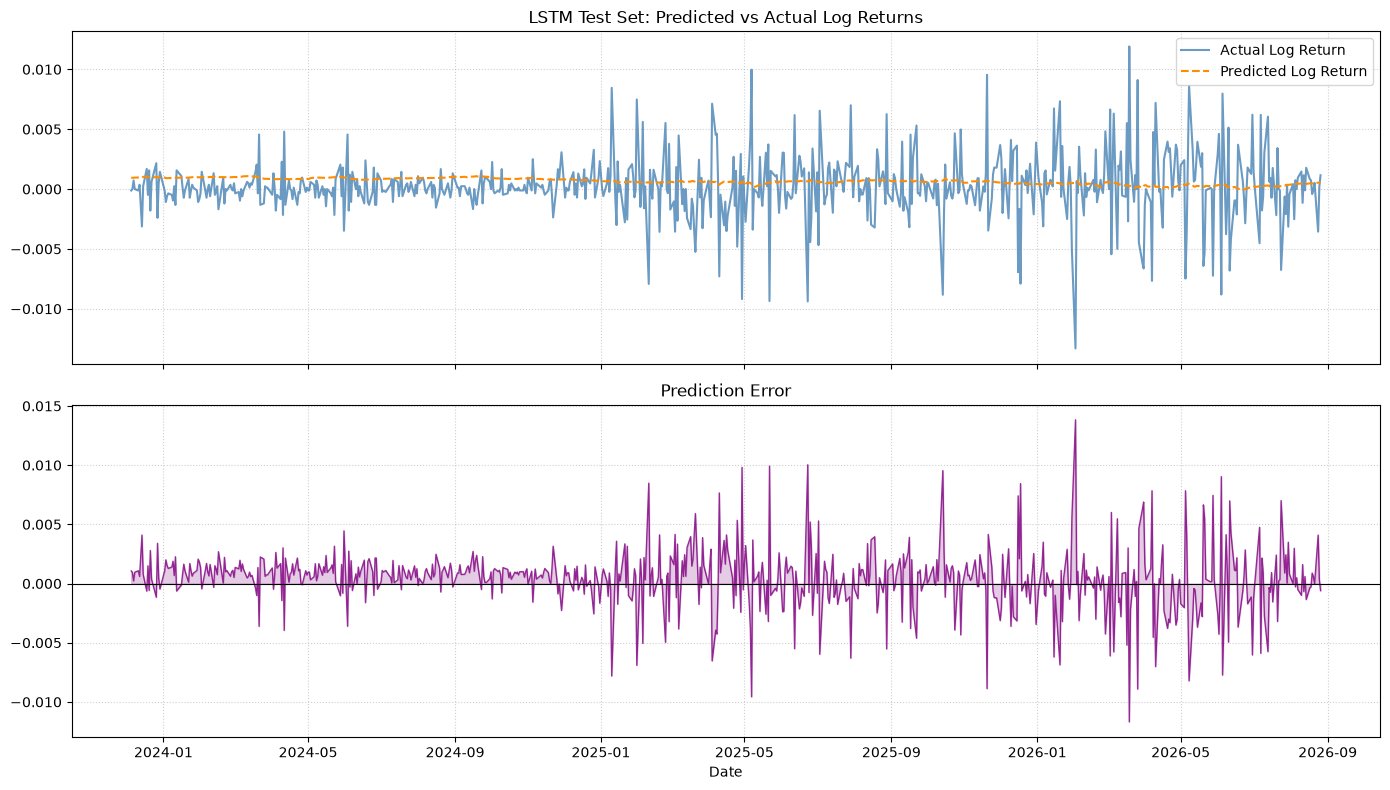

In [33]:
# ────────────────────────────────────────────────────────────────────────────
# Plot LSTM predictions vs actuals for Log Returns (Test set)
# ────────────────────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
test_result = lstm_eval_results["test"]

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(test_result["dates"], test_result["targets"], label="Actual Log Return", color="steelblue", alpha=0.8)
axes[0].plot(test_result["dates"], test_result["predictions"], label="Predicted Log Return", color="darkorange", linestyle="--", linewidth=1.5)
axes[0].set_title("LSTM Test Set: Predicted vs Actual Log Returns")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

errors = test_result["predictions"] - test_result["targets"]
# Use plot and fill_between instead of bar to avoid empty plots on datetime axes
axes[1].plot(test_result["dates"], errors, color="purple", linewidth=1.0, alpha=0.8)
axes[1].fill_between(test_result["dates"], 0, errors, color="purple", alpha=0.2)
axes[1].axhline(y=0, color="black", linewidth=0.8)
axes[1].set_title("Prediction Error")
axes[1].set_xlabel("Date")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


## EUR/USD LSTM Model (Target: Log Returns + Directional Loss)

Applying the exact same directional LSTM architecture to the EUR/USD exchange rate.
We calculate technical indicators centered on EUR as the target.

In [54]:
# ────────────────────────────────────────────────────────────────────────────
# Prepare technical-indicator data for EUR/USD
# ────────────────────────────────────────────────────────────────────────────

eur_df = calculate_technical_indicators(full_df, target_column="EUR")
eur_df["TARGET_LOG_RETURN_NEXT"] = eur_df["Log_Returns"].shift(-1)
eur_df = eur_df.dropna()

EUR_FEATURE_COLUMNS = ["INR", "JPY", "FFER", "US10YY"]
EUR_LSTM_FEATURE_COLS = [
    "EUR",
    *EUR_FEATURE_COLUMNS,
    "MA_5", "MA_10", "MA_30", "MA_50", "MA_100",
    "EMA_5", "EMA_10", "EMA_30", "EMA_50", "EMA_100",
    "RSI",
    "BB_Middle", "BB_Upper", "BB_Lower",
    "Volatility",
    "ATR_14_proxy", "ATR_%_proxy",
    "Log_Returns",
]

print(f"EUR LSTM dataframe shape: {eur_df.shape}")


EUR LSTM dataframe shape: (6805, 25)


In [55]:
# ────────────────────────────────────────────────────────────────────────────
# Create windowed dataloaders predicting EUR Log Returns
# ────────────────────────────────────────────────────────────────────────────
eur_lstm_loaders = create_time_series_dataloaders(
    data=eur_df,
    target_column="Log_Returns",
    feature_columns=EUR_LSTM_FEATURE_COLS,
    window_size=LSTM_WINDOW_SIZE,
    offset=0,
    target_size=1,
    stride=1,
    batch_size=LSTM_BATCH_SIZE,
    train_fraction=TRAIN_FRACTION,
    validation_fraction=VALIDATION_FRACTION,
    scale_features=True,
    scale_targets=True,
    shuffle_train=True,
    device=DEVICE,
)
print(f"Train samples: {len(eur_lstm_loaders['train_dataset'])}")


Train samples: 5434


In [56]:
# ────────────────────────────────────────────────────────────────────────────
# Initialize & Train EUR LSTM Model
# ────────────────────────────────────────────────────────────────────────────
eur_lstm_model = LSTMForecaster(
    input_size=len(EUR_LSTM_FEATURE_COLS),
    hidden_size=LSTM_HIDDEN_SIZE,
    num_layers=LSTM_NUM_LAYERS,
    dropout=LSTM_DROPOUT,
).to(DEVICE)

eur_lstm_optimizer = optim.Adam(eur_lstm_model.parameters(), lr=LSTM_LR, weight_decay=1e-5)
eur_lstm_loss_fn = BigMoveAwareLoss(dir_penalty=0.5, mag_penalty=2.0, sigma_threshold=1.5)
eur_lstm_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    eur_lstm_optimizer, mode="min", factor=0.5, patience=4, verbose=True
)

eur_lstm_history = train_torch_model_dataloader(
    model=eur_lstm_model,
    optimizer=eur_lstm_optimizer,
    loss_function=eur_lstm_loss_fn,
    train_loader=eur_lstm_loaders["train_loader"],
    val_loader=eur_lstm_loaders["val_loader"],
    epochs=LSTM_EPOCHS,
    device=DEVICE,
    log_every=10,
    scheduler=eur_lstm_scheduler,
    early_stopping_patience=LSTM_PATIENCE,
)


c:\Users\xprin\Desktop\AIML\.venv\Lib\site-packages\torch\optim\lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 10/80 - Train Loss: 7.3751, Val Loss: 4.4487
Early stopping triggered at epoch 13. Restoring best weights (Val Loss: 4.2913).


In [57]:
# ────────────────────────────────────────────────────────────────────────────
# Evaluate EUR LSTM and store predictions
# ────────────────────────────────────────────────────────────────────────────
eur_lstm_eval_results = predict_and_store_window_model(
    model=eur_lstm_model,
    model_name="EUR LSTM + Tech Indicators (Directional)",
    loaders_dict=eur_lstm_loaders,
    model_results=model_results,
    device=DEVICE,
    output_path=str(RESULTS_PATH),
    metadata={"window_size": LSTM_WINDOW_SIZE, "target": "EUR_Log_Returns"},
    price_data=eur_df,
    price_column="EUR",
)

for split_name in ["train", "validation", "test"]:
    result = eur_lstm_eval_results.get(split_name)
    if result is not None:
        m = result["metrics"]
        print(f"{split_name.capitalize():>12s} — MAE: {m['mae']:.5f}  RMSE: {m['rmse']:.5f}  Dir. Acc: {m['directional_accuracy']:.2f}%")


       Train — MAE: 0.00446  RMSE: 0.00600  Dir. Acc: 74.77%
  Validation — MAE: 0.00382  RMSE: 0.00508  Dir. Acc: 74.23%
        Test — MAE: 0.00313  RMSE: 0.00429  Dir. Acc: 75.29%


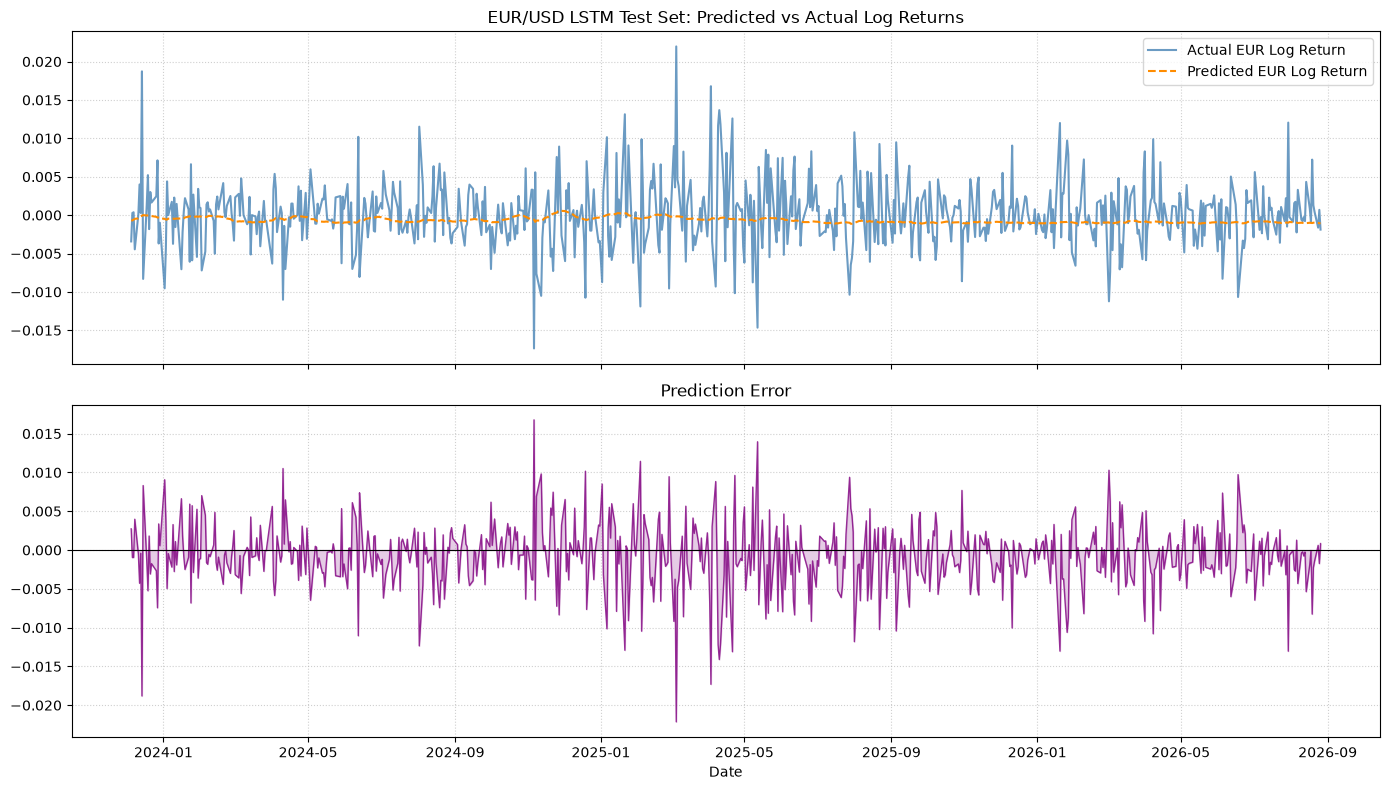

In [58]:
# ────────────────────────────────────────────────────────────────────────────
# Plot EUR LSTM predictions vs actuals (Test set)
# ────────────────────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
eur_test_result = eur_lstm_eval_results["test"]

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(eur_test_result["dates"], eur_test_result["targets"], label="Actual EUR Log Return", color="steelblue", alpha=0.8)
axes[0].plot(eur_test_result["dates"], eur_test_result["predictions"], label="Predicted EUR Log Return", color="darkorange", linestyle="--", linewidth=1.5)
axes[0].set_title("EUR/USD LSTM Test Set: Predicted vs Actual Log Returns")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

errors = eur_test_result["predictions"] - eur_test_result["targets"]
axes[1].plot(eur_test_result["dates"], errors, color="purple", linewidth=1.0, alpha=0.8)
axes[1].fill_between(eur_test_result["dates"], 0, errors, color="purple", alpha=0.2)
axes[1].axhline(y=0, color="black", linewidth=0.8)
axes[1].set_title("Prediction Error")
axes[1].set_xlabel("Date")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


### CALCULATE PROFITS

In [59]:
from utils import AdvancedProfitCalculator

In [60]:
eur_lstm_eval_results["validation"].keys()

dict_keys(['predictions', 'targets', 'metrics', 'dates'])

In [61]:
print(eur_lstm_eval_results["validation"]["predictions"].size)
print(eur_lstm_eval_results["validation"]["targets"].size)
print(eur_lstm_eval_results["validation"]["dates"].size)

680
680
680


           INSTITUTIONAL QUANT TRADING PERFORMANCE REPORT
CAPITAL & RETURNS:
  Initial Capital        : $10,000.00
  Final Portfolio Value  : $22,035.83
  Strategy Net Return    : +120.36%
  Benchmark (Buy & Hold) : -9.80%
  Strategy Alpha         : +130.15%
  Annualized CAGR        : +34.02%
--------------------------------------------------------------------------------
TRADE EXECUTION & WIN/LOSS METRICS:
  Total Trades Executed  : 603 (Long: 262, Short: 341, Neutral: 77)
  Winning Trades         : 297 (49.25%)
  Losing Trades          : 306 (50.75%)
  Average Win ($)        : $152.00
  Average Loss ($)       : $108.20
  Realized Risk/Reward   : 1.40
  Gross Profit           : $45,145.25
  Gross Loss             : $33,109.43
  Profit Factor          : 1.36
  Trade Expectancy       : $19.96 per trade
--------------------------------------------------------------------------------
RISK-ADJUSTED METRICS:
  Max Drawdown           : -10.74%
  Annualized Sharpe      : 1.86
  Annualized Sor

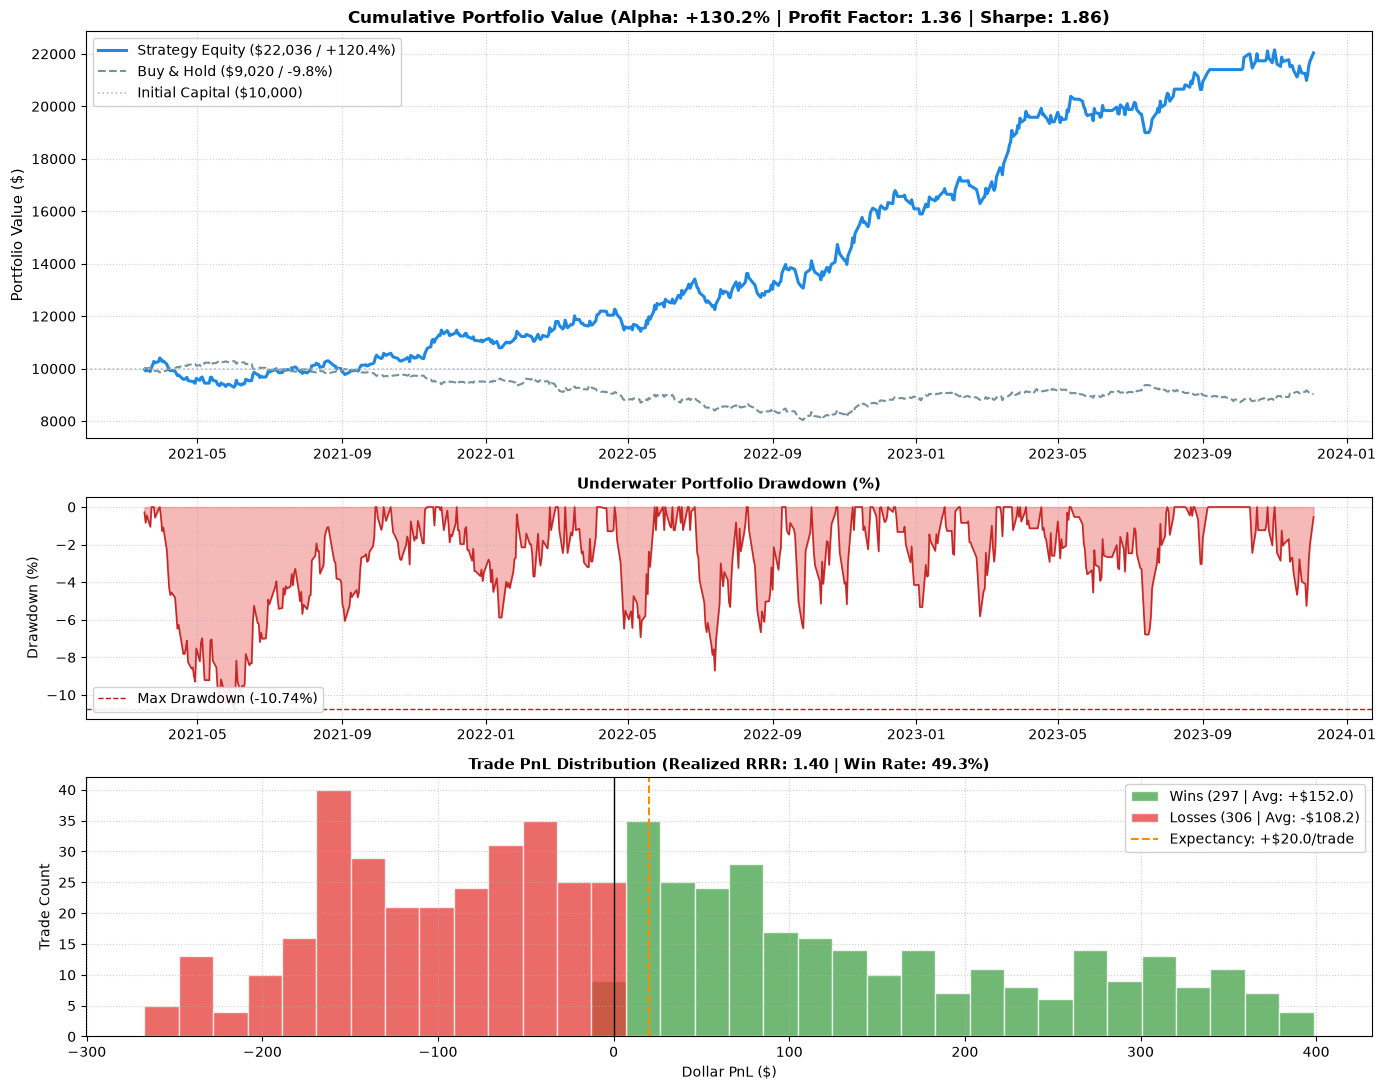

In [62]:
# 1. Instantiate the quantitative backtester
# You can test on "validation" or "test"
split = "validation"

calculator = AdvancedProfitCalculator(
    predictions=eur_lstm_eval_results[split]["predictions"],
    actual_returns=eur_lstm_eval_results[split]["targets"],
    initial_capital=10000.0,
    stop_loss=0.004,         # 0.40% Stop Loss
    risk_reward_ratio=2.0,   # 1:2 RRR -> Auto-sets Take Profit to 0.80%
    threshold=0.0001,        # 1-pip deadzone filter (avoids noise below 0.01%)
    fee_per_trade=0.0001,    # 1-pip round-trip transaction friction
    risk_per_trade=0.02,     # Risk exactly 2% of portfolio equity per trade
    max_leverage=3.0,        # Conservative 3x forex leverage cap
    dates=eur_lstm_eval_results[split]["dates"],
)

# 2. Print institutional performance summary
calculator.summary()

# 3. Render 3-panel quant trading dashboard:
#    - Panel 1: Portfolio Equity Curve vs Buy & Hold Benchmark
#    - Panel 2: Underwater Drawdown Curve (%)
#    - Panel 3: Trade PnL Distribution (Histogram of Wins & Losses)
calculator.plot()

### GENETIC ALGORITHM FOR STRATEGY OPTIMISATION

         GENETIC ALGORITHM HYPERPARAMETER OPTIMIZATION STARTING
Population Size : 40 | Generations: 25 | Objective: CALMAR
Optimizing Genes: stop_loss, risk_reward_ratio, threshold, risk_per_trade, max_leverage
--------------------------------------------------------------------------------
Gen  0/25 | Best Fitness:    6.37 (Avg:   1.13) | SL: 0.0024 | RRR: 2.66 | Thresh: 0.00025 | Risk%: 2.28%
Gen  5/25 | Best Fitness:   16.60 (Avg:   9.42) | SL: 0.0020 | RRR: 3.50 | Thresh: 0.00002 | Risk%: 3.03%
Gen 10/25 | Best Fitness:   18.32 (Avg:  15.80) | SL: 0.0020 | RRR: 3.49 | Thresh: 0.00000 | Risk%: 1.81%
Gen 15/25 | Best Fitness:   18.38 (Avg:  17.15) | SL: 0.0020 | RRR: 3.50 | Thresh: 0.00000 | Risk%: 1.46%
Gen 20/25 | Best Fitness:   18.38 (Avg:  16.33) | SL: 0.0020 | RRR: 3.50 | Thresh: 0.00000 | Risk%: 1.75%
Gen 24/25 | Best Fitness:   18.38 (Avg:  17.20) | SL: 0.0020 | RRR: 3.50 | Thresh: 0.00000 | Risk%: 1.37%
------------------------------------------------------------------------

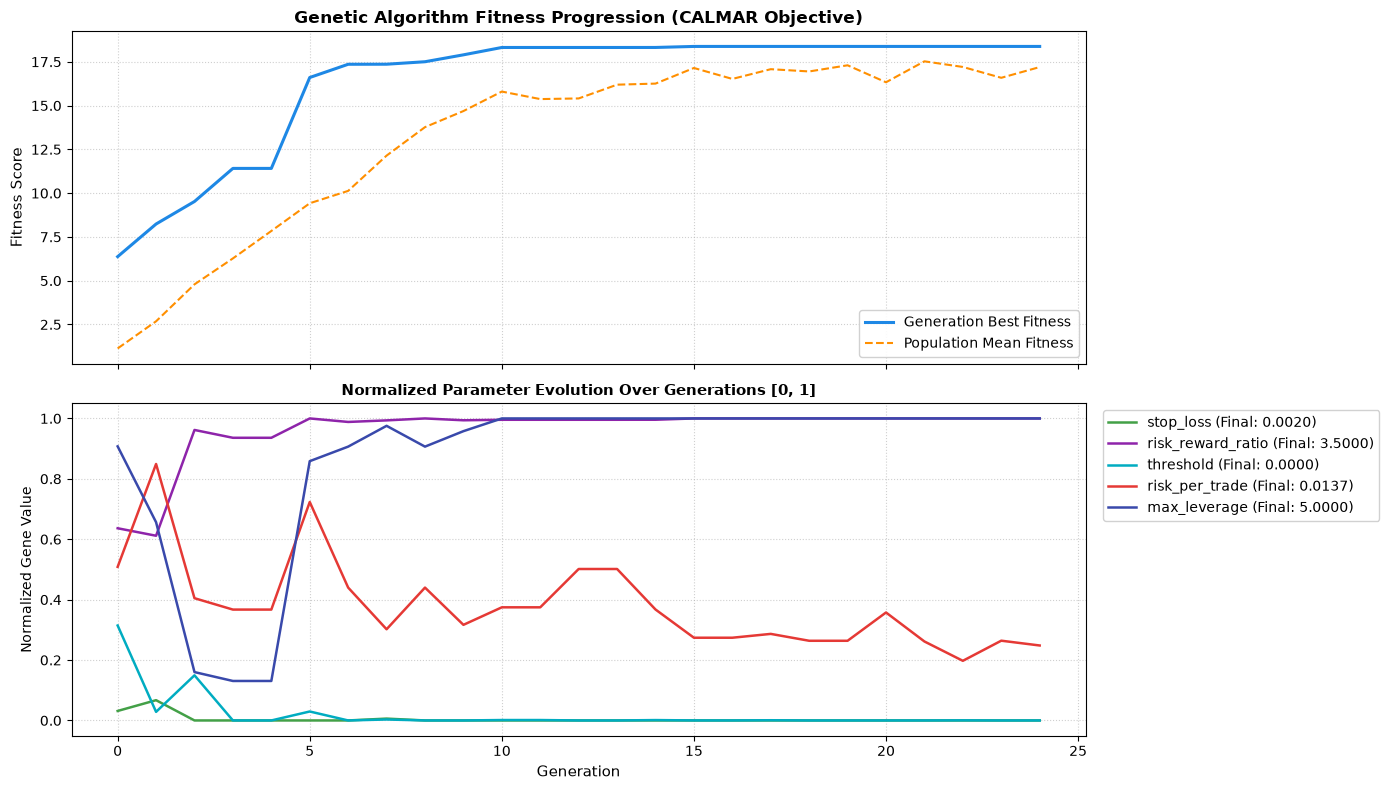

           INSTITUTIONAL QUANT TRADING PERFORMANCE REPORT
CAPITAL & RETURNS:
  Initial Capital        : $10,000.00
  Final Portfolio Value  : $195,857.02
  Strategy Net Return    : +1858.57%
  Benchmark (Buy & Hold) : -9.80%
  Strategy Alpha         : +1868.37%
  Annualized CAGR        : +201.15%
--------------------------------------------------------------------------------
TRADE EXECUTION & WIN/LOSS METRICS:
  Total Trades Executed  : 680 (Long: 286, Short: 394, Neutral: 0)
  Winning Trades         : 343 (50.44%)
  Losing Trades          : 337 (49.56%)
  Average Win ($)        : $996.44
  Average Loss ($)       : $462.68
  Realized Risk/Reward   : 2.15
  Gross Profit           : $341,778.73
  Gross Loss             : $155,921.72
  Profit Factor          : 2.19
  Trade Expectancy       : $273.32 per trade
--------------------------------------------------------------------------------
RISK-ADJUSTED METRICS:
  Max Drawdown           : -10.95%
  Annualized Sharpe      : 4.64
  Annualiz

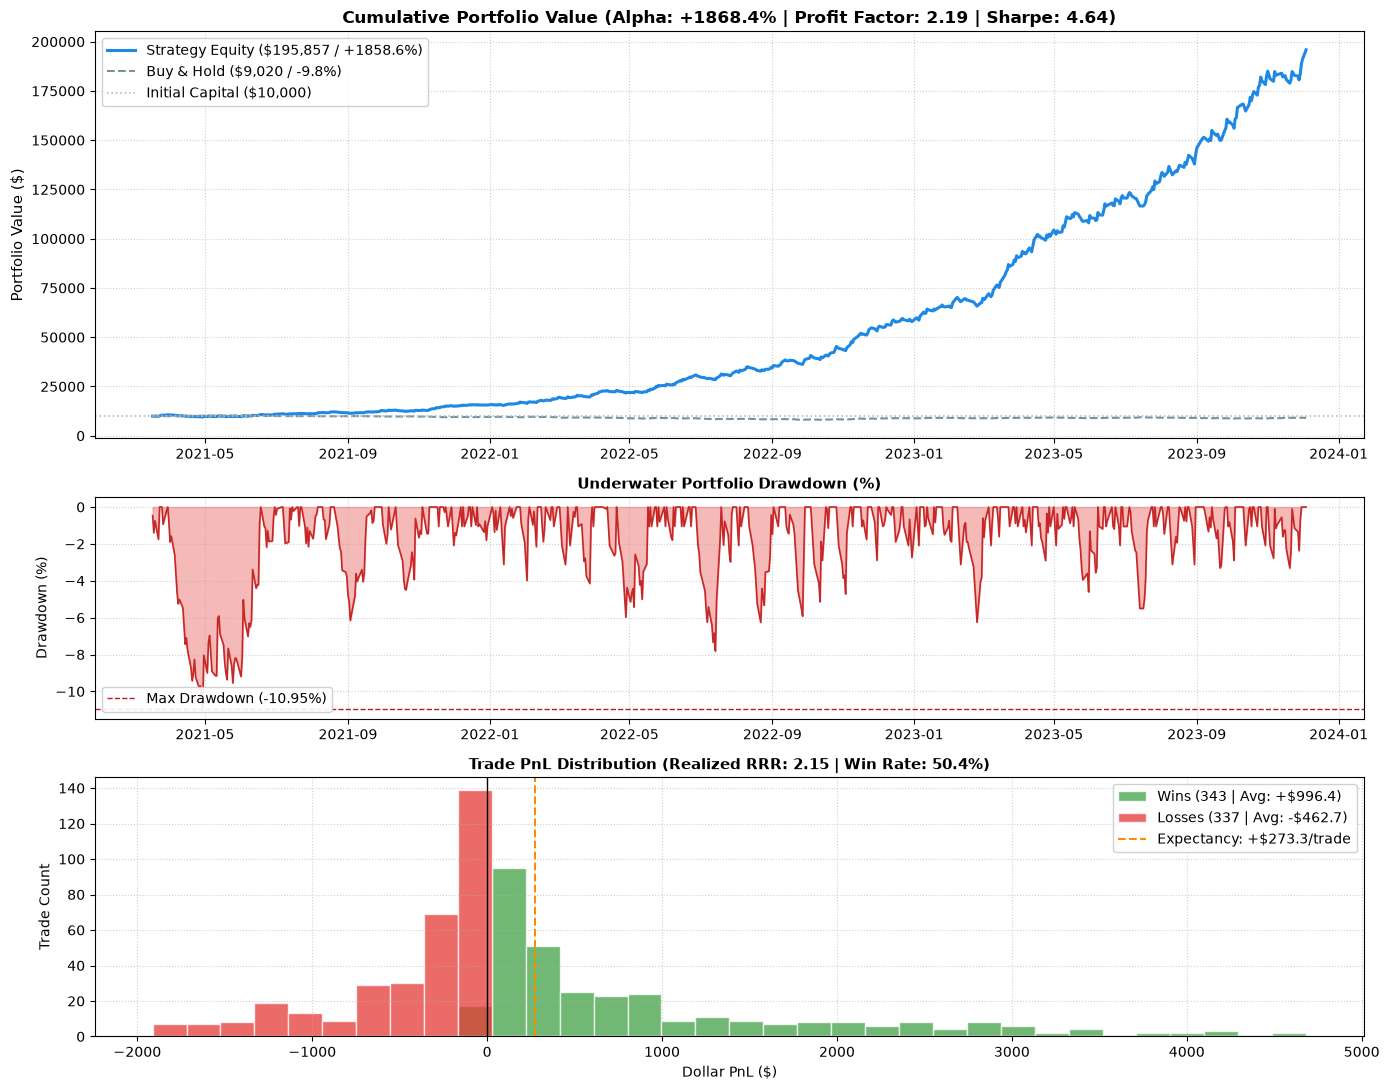

In [63]:
from utils import optimize_strategy_ga

# 1. Run the Genetic Algorithm on Validation Set predictions
val_preds = eur_lstm_eval_results["validation"]["predictions"]
val_targets = eur_lstm_eval_results["validation"]["targets"]
val_dates = eur_lstm_eval_results["validation"]["dates"]

ga_result = optimize_strategy_ga(
    predictions=val_preds,
    actual_returns=val_targets,
    fitness_metric="calmar",  # 'composite', 'sharpe', 'sortino', 'calmar', or 'profit_factor'
    population_size=40,          # 40 strategy candidates per generation
    generations=25,              # 25 evolutionary cycles
    fee_per_trade=0.0001,        # 1-pip transaction cost
    dates=val_dates,
    random_state=42,
    verbose=True,
)

# 2. View the GA convergence trajectories over generations
ga_result["optimizer"].plot_convergence()

# 3. View the best-evolved strategy performance & chart
best_calculator = ga_result["best_calculator"]
best_calculator.summary()
best_calculator.plot()

### TESTING GA RESULTS ON TEST DATA

           INSTITUTIONAL QUANT TRADING PERFORMANCE REPORT
CAPITAL & RETURNS:
  Initial Capital        : $10,000.00
  Final Portfolio Value  : $50,888.64
  Strategy Net Return    : +408.89%
  Benchmark (Buy & Hold) : +6.99%
  Strategy Alpha         : +401.90%
  Annualized CAGR        : +82.59%
--------------------------------------------------------------------------------
TRADE EXECUTION & WIN/LOSS METRICS:
  Total Trades Executed  : 670 (Long: 27, Short: 643, Neutral: 11)
  Winning Trades         : 325 (48.51%)
  Losing Trades          : 345 (51.49%)
  Average Win ($)        : $344.72
  Average Loss ($)       : $206.22
  Realized Risk/Reward   : 1.67
  Gross Profit           : $112,034.01
  Gross Loss             : $71,145.37
  Profit Factor          : 1.57
  Trade Expectancy       : $61.03 per trade
--------------------------------------------------------------------------------
RISK-ADJUSTED METRICS:
  Max Drawdown           : -7.86%
  Annualized Sharpe      : 3.01
  Annualized Sort

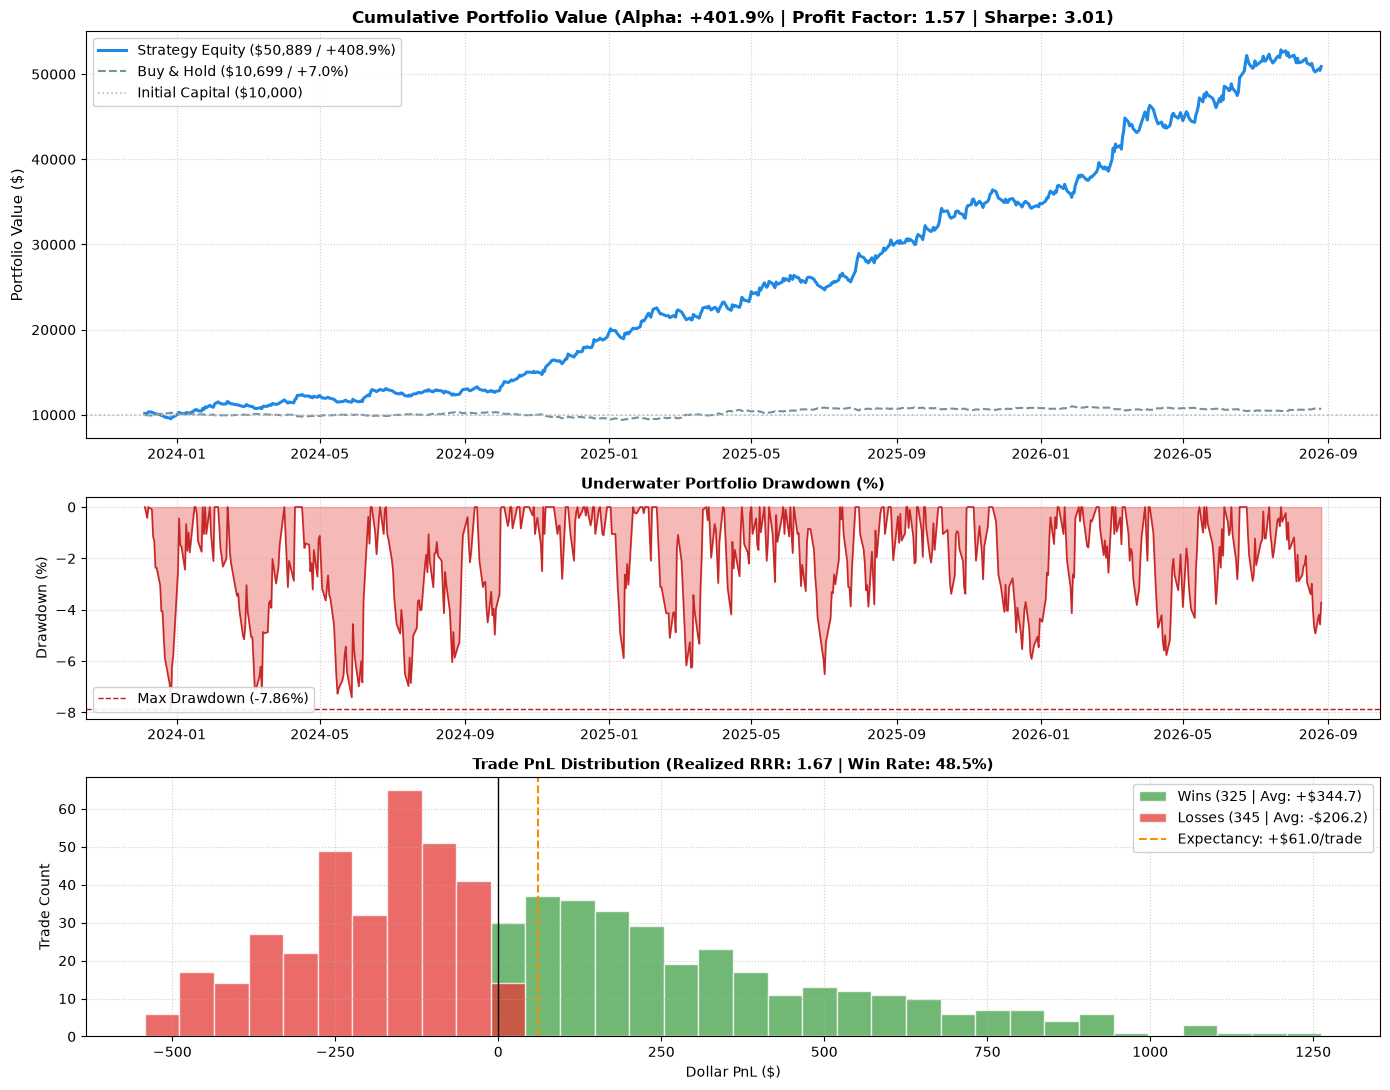

In [64]:
# 1. Instantiate the quantitative backtester
# You can test on "validation" or "test"

# Optimal Parameters:
#   stop_loss         : 0.00200 (0.200%)
#   risk_reward_ratio : 3.50
#   threshold         : 0.00004 (0.004%)
#   risk_per_trade    : 0.02746 (2.746%)
#   max_leverage      : 5.00
#   take_profit       : 0.00700 (0.700%)
split = "test"

calculator = AdvancedProfitCalculator(
    predictions=eur_lstm_eval_results[split]["predictions"],
    actual_returns=eur_lstm_eval_results[split]["targets"],
    initial_capital=10000.0,
    stop_loss=0.00200,         # 0.200% Stop Loss
    risk_reward_ratio=3.50,   # 1:3.5 RRR -> Auto-sets Take Profit to 0.700%
    threshold=0.00004,        # 0.004% deadzone filter (avoids noise below 0.004%)
    fee_per_trade=0.0001,    # 1-pip round-trip transaction friction
    risk_per_trade=0.02746,     # Risk exactly 2% of portfolio equity per trade
    max_leverage=5.00,        # Conservative 3x forex leverage cap
    dates=eur_lstm_eval_results[split]["dates"],
    take_profit=0.00700,       # 0.700% Take Profit (auto-calculated from RRR, but can be overridden here)
)

# 2. Print institutional performance summary
calculator.summary()

# 3. Render 3-panel quant trading dashboard:
#    - Panel 1: Portfolio Equity Curve vs Buy & Hold Benchmark
#    - Panel 2: Underwater Drawdown Curve (%)
#    - Panel 3: Trade PnL Distribution (Histogram of Wins & Losses)
calculator.plot()

### TRAINING FOR VAL ALSO

In [ ]:
import torch
from torch.utils.data import DataLoader
from utils import train_on_val_data, train_torch_model_with_val_data

# Note: The functions `train_on_val_data` and `train_torch_model_with_val_data`
# are defined in utils.py and imported above. Below is the standalone definition
# for reference and direct customization:

def train_on_val_data(
    model,
    val_loader,
    loss_function,
    optimizer=None,
    epochs=15,
    lr=1e-4,
    device=None,
    log_every=5,
    scheduler=None,
    clip_grad_norm=None,
    shuffle=True,
):
    """
    Train / fine-tune a model on the validation data split.
    
    In financial time-series forecasting, models are initially trained on the training
    split and evaluated/tuned on the validation split. Before predicting on the test set,
    continuing training on the validation set adapts the model's parameters and internal
    states to the market regime immediately preceding the test period.
    
    Parameters
    ----------
    model : torch.nn.Module
        The PyTorch model to train (e.g. LSTMForecaster).
    val_loader : torch.utils.data.DataLoader or dict
        DataLoader containing validation batches, or a dict containing a 'val_loader' key.
    loss_function : callable
        Loss function (e.g., BigMoveAwareLoss or nn.MSELoss).
    optimizer : torch.optim.Optimizer, optional
        Optimizer for training. If None, an Adam optimizer with weight_decay=1e-5
        and learning rate `lr` is automatically instantiated.
    epochs : int, default=15
        Number of epochs to train on the validation data.
    lr : float, default=1e-4
        Learning rate if optimizer is not provided. Defaults to 1e-4 (fine-tuning rate).
    device : torch.device or str, optional
        Target device (CPU or CUDA). Defaults to model device or CUDA if available.
    log_every : int, default=5
        Frequency (in epochs) to print the average epoch loss. Set to 0 to disable.
    scheduler : torch.optim.lr_scheduler, optional
        Optional learning rate scheduler stepped after each epoch.
    clip_grad_norm : float, optional
        If specified, gradients are clipped to this maximum norm.
    shuffle : bool, default=True
        Whether to shuffle validation batches during training for improved gradient variance.
        
    Returns
    -------
    dict
        Dictionary containing:
        - 'val_train_losses': list of average training losses per epoch on the validation data.
    """
    if isinstance(val_loader, dict):
        if "val_loader" in val_loader:
            val_loader = val_loader["val_loader"]
        elif "validation" in val_loader:
            val_loader = val_loader["validation"]
        else:
            raise KeyError("val_loader dict must contain 'val_loader' or 'validation' key.")

    if val_loader is None or len(val_loader) == 0:
        raise ValueError("val_loader is empty or None.")

    target_device = device or (
        next(model.parameters()).device
        if list(model.parameters())
        else (torch.device("cuda" if torch.cuda.is_available() else "cpu"))
    )
    model.to(target_device)

    if optimizer is None:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)

    loader_to_use = val_loader
    if shuffle and hasattr(val_loader, "dataset") and val_loader.dataset is not None:
        batch_size = getattr(val_loader, "batch_size", 32)
        loader_to_use = DataLoader(
            val_loader.dataset,
            batch_size=batch_size,
            shuffle=True,
            num_workers=getattr(val_loader, "num_workers", 0),
            pin_memory=getattr(val_loader, "pin_memory", False),
        )

    val_train_losses = []

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        num_batches = 0

        for batch_x, batch_y in loader_to_use:
            batch_x = batch_x.to(target_device)
            batch_y = batch_y.to(target_device)

            optimizer.zero_grad()
            predictions = model(batch_x)
            if predictions.shape != batch_y.shape:
                if predictions.ndim == 2 and predictions.shape[1] == 1 and batch_y.ndim == 1:
                    predictions = predictions.squeeze(1)
                elif batch_y.ndim == 2 and batch_y.shape[1] == 1 and predictions.ndim == 1:
                    predictions = predictions.unsqueeze(1)

            loss = loss_function(predictions, batch_y)
            loss.backward()

            if clip_grad_norm is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad_norm)

            optimizer.step()

            running_loss += loss.item()
            num_batches += 1

        epoch_loss = running_loss / max(num_batches, 1)
        val_train_losses.append(epoch_loss)

        if scheduler is not None:
            if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(epoch_loss)
            else:
                scheduler.step()

        if log_every and (epoch + 1) % log_every == 0:
            print(f"Val Training Epoch {epoch + 1}/{epochs} - Loss: {epoch_loss:.5f}")

    return {
        "val_train_losses": val_train_losses,
    }


In [ ]:
# ────────────────────────────────────────────────────────────────────────────
# Train eur_lstm_model on the validation data split
# ────────────────────────────────────────────────────────────────────────────
val_history = train_on_val_data(
    model=eur_lstm_model,
    val_loader=eur_lstm_loaders["val_loader"],
    loss_function=eur_lstm_loss_fn,
    epochs=15,             # 15 fine-tuning epochs on validation data
    lr=1e-4,              # Slightly lower learning rate for stable fine-tuning
    device=DEVICE,
    log_every=5,
    shuffle=True,
)


In [ ]:
# ────────────────────────────────────────────────────────────────────────────
# Re-evaluate model on test data after training on validation set
# ────────────────────────────────────────────────────────────────────────────
eur_lstm_eval_results_val_trained = predict_and_store_window_model(
    model=eur_lstm_model,
    model_name="EUR LSTM + Val Training (Directional)",
    loaders_dict=eur_lstm_loaders,
    model_results=model_results,
    device=DEVICE,
    output_path=str(RESULTS_PATH),
    metadata={"window_size": LSTM_WINDOW_SIZE, "target": "EUR_Log_Returns", "trained_on_val": True},
    price_data=eur_df,
    price_column="EUR",
)

# Compare Test metrics before vs after training on val data
print("\n=== Test Metrics Comparison: Before vs After Validation Training ===")
m_before = eur_lstm_eval_results["test"]["metrics"]
m_after = eur_lstm_eval_results_val_trained["test"]["metrics"]
print(f"MAE          : {m_before['mae']:.5f}  ->  {m_after['mae']:.5f}")
print(f"RMSE         : {m_before['rmse']:.5f}  ->  {m_after['rmse']:.5f}")
print(f"Dir. Accuracy: {m_before['directional_accuracy']:.2f}%  ->  {m_after['directional_accuracy']:.2f}%")


In [ ]:
# ────────────────────────────────────────────────────────────────────────────
# Backtest using GA optimal parameters on updated Test predictions
# ────────────────────────────────────────────────────────────────────────────
split = "test"

calculator_val_trained = AdvancedProfitCalculator(
    predictions=eur_lstm_eval_results_val_trained[split]["predictions"],
    actual_returns=eur_lstm_eval_results_val_trained[split]["targets"],
    initial_capital=10000.0,
    stop_loss=0.00200,         # 0.200% Stop Loss from GA
    risk_reward_ratio=3.50,   # 1:3.5 RRR from GA
    threshold=0.00004,        # 0.004% deadzone filter from GA
    fee_per_trade=0.0001,    # 1-pip transaction friction
    risk_per_trade=0.02746,     # 2.746% risk per trade from GA
    max_leverage=5.00,        # 5x leverage cap from GA
    dates=eur_lstm_eval_results_val_trained[split]["dates"],
    take_profit=0.00700,       # 0.700% Take Profit
)

# Institutional performance summary & 3-panel dashboard
calculator_val_trained.summary()
calculator_val_trained.plot()
